In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, cross_val_predict, cross_validate
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.metrics import mean_squared_log_error, r2_score

from sklearn.linear_model import Lasso, LinearRegression, TweedieRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR 
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor

from skopt.space import Real, Categorical, Integer
from skopt.utils import use_named_args
from skopt import gp_minimize

from yellowbrick.model_selection import CVScores, ValidationCurve
from yellowbrick.regressor import PredictionError, ResidualsPlot

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# **Model Selection & Hyperparameter Tuning**

## **Read in Data**

In [2]:
y = pd.read_csv('../data/y.csv')

y = np.array(y)
y_normalized = MinMaxScaler().fit_transform(y)
y_log = np.array(np.log(y)).reshape(-1, 1)
y_log_normalized = MinMaxScaler().fit_transform(y_log)

y = y.ravel()
y_normalized = y_normalized.ravel()
y_log = y_log.ravel()
y_log_normalized = y_log_normalized.ravel()



y_train = pd.read_csv('../data/y_train.csv')

y_train = np.array(y_train)
y_train_normalized = MinMaxScaler().fit_transform(y_train)
y_train_log = np.array(np.log(y_train)).reshape(-1, 1)
y_train_log_normalized = MinMaxScaler().fit_transform(y_train_log)

y_train = y_train.ravel()
y_train_normalized = y_train_normalized.ravel()
y_train_log = y_train_log.ravel()
y_train_log_normalized = y_train_log_normalized.ravel()



y_test = pd.read_csv('../data/y_test.csv')

y_test = np.array(y_test)
y_test_normalized = MinMaxScaler().fit_transform(y_test)
y_test_log = np.array(np.log(y_test)).reshape(-1, 1)
y_test_log_normalized = MinMaxScaler().fit_transform(y_test_log)

y_test = y_test.ravel()
y_test_normalized = y_test_normalized.ravel()
y_test_log = y_test_log.ravel()
y_test_log_normalized = y_test_log_normalized.ravel()

In [3]:
automatic_selected_features = pd.read_csv('../data/selected_features.csv').iloc[:, 0].tolist()

columns = pd.read_csv('../data/X.csv').columns
other_features = columns[columns.str.contains('PBA')].tolist()
other_features.extend(['SQFT', 'NFLOOR', 'CDD65', 'HDD65'])

X = pd.read_csv('../data/X.csv')
X_train = pd.read_csv('../data/X_train.csv')
X_test = pd.read_csv('../data/X_test.csv')

In [4]:
with open('../data/divisions.npy', 'rb') as f:
    divisions = np.load(f)

## **Models**

### **Linear Regression**

In [5]:
def linear_regressor_gridsearch(features, target, scoring_metric):
    
    logo = LeaveOneGroupOut()
    linear_regressor = LinearRegression(n_jobs=-1)

    parameters = {
        'fit_intercept':[True,False]}

    linear_regressor_gridsearch = GridSearchCV(linear_regressor, parameters, scoring=scoring_metric, cv=logo, n_jobs=-1)
    linear_regressor_gridsearch.fit(X[features], y=target, groups=divisions)
    print("Best parameters of the OLS regressor are: %s" % linear_regressor_gridsearch.best_params_)
    print("Best score with the best parameters is: %s" % linear_regressor_gridsearch.best_score_)
    print("Average score is: %s\n" % linear_regressor_gridsearch.cv_results_["mean_test_score"].mean())
    
    
def linear_regressor_crossvalidation(features, target, target_train, target_test, scoring_metric):
    
    logo = LeaveOneGroupOut()
    logo_cv = logo.split(X[features], target, groups=divisions)
    linear_regressor = LinearRegression(fit_intercept=True, n_jobs=-1)

    y_predict1 = cross_val_predict(linear_regressor, X[features], target, groups=divisions, cv=logo_cv, n_jobs=-1)
    scores = cross_validate(linear_regressor, X[features], target, groups=divisions, cv=logo, scoring=scoring_metric, return_estimator=True)
    
    linear_regressor.fit(X_train[features], target_train)
    y_predict2 = linear_regressor.predict(X_test[features])
    
    if scoring_metric is 'r2':
        print('CrossValPredict R2 is %s' % r2_score(target, y_predict1))
        print('TrainTestSplit R2 is %s' % r2_score(target_test, y_predict2))
        print('Average R2 is %s' % scores['test_score'].mean())
        print('Best R2 is %s\n' % scores['test_score'].max())
    elif scoring_metric is 'neg_mean_squared_log_error':
        print('CrossValPredict MSLE is %s' % mean_squared_log_error(target, y_predict1))
        print('TrainTestSplit MSLE is %s' % mean_squared_log_error(target_test, y_predict2))
        print('Average MSLE is %s' % scores['test_score'].mean())
        print('Best MSLE is %s\n' % scores['test_score'].max())
        
    return scores['test_score'].mean()

In [6]:
linear_regressor_gridsearch(automatic_selected_features, y, 'r2')
linear_regressor_gridsearch(automatic_selected_features, y_normalized, 'r2')
linear_regressor_gridsearch(automatic_selected_features, y_log, 'r2')
linear_regressor_gridsearch(automatic_selected_features, y_log_normalized, 'r2')

print('\n')

linear_regressor_gridsearch(other_features, y, 'r2')
linear_regressor_gridsearch(other_features, y_normalized, 'r2')
linear_regressor_gridsearch(other_features, y_log, 'r2')
linear_regressor_gridsearch(other_features, y_log_normalized, 'r2')

print('\n')

average_score_automaticfeatures_nontransformed_ols = linear_regressor_crossvalidation(automatic_selected_features, y, y_train, y_test, 'r2')
average_score_automaticfeatures_normalized_ols = linear_regressor_crossvalidation(automatic_selected_features, y_normalized, y_train_normalized, y_test_normalized, 'r2')
average_score_automaticfeatures_log_ols = linear_regressor_crossvalidation(automatic_selected_features, y_log, y_train_log, y_test_log, 'r2')
average_score_automaticfeatures_log_normalized_ols = linear_regressor_crossvalidation(automatic_selected_features, y_log_normalized, y_train_log_normalized, y_test_log_normalized, 'r2')

print('\n')

average_score_otherfeatures_nontransformed_ols = linear_regressor_crossvalidation(other_features, y, y_train, y_test, 'r2')
average_score_otherfeatures_normalized_ols = linear_regressor_crossvalidation(other_features, y_normalized, y_train_normalized, y_test_normalized, 'r2')
average_score_otherfeatures_log_ols = linear_regressor_crossvalidation(other_features, y_log, y_train_log, y_test_log, 'r2')
average_score_otherfeatures_log_normalized_ols = linear_regressor_crossvalidation(other_features, y_log_normalized, y_train_log_normalized, y_test_log_normalized, 'r2')

Best parameters of the OLS regressor are: {'fit_intercept': True}
Best score with the best parameters is: 0.6876649185135766
Average score is: 0.6842771364560372

Best parameters of the OLS regressor are: {'fit_intercept': True}
Best score with the best parameters is: 0.6876649185135767
Average score is: 0.6842769770539734

Best parameters of the OLS regressor are: {'fit_intercept': True}
Best score with the best parameters is: 0.47157065428672534
Average score is: -4.790168563436409

Best parameters of the OLS regressor are: {'fit_intercept': True}
Best score with the best parameters is: 0.47157065428672534
Average score is: -1.6416127172523092



Best parameters of the OLS regressor are: {'fit_intercept': False}
Best score with the best parameters is: 0.6242580110334051
Average score is: 0.6242296716947489

Best parameters of the OLS regressor are: {'fit_intercept': True}
Best score with the best parameters is: 0.624367975368171
Average score is: 0.624312993200788

Best parameters of

In [7]:
print(pd.DataFrame(list(zip(['Non Transformed Target', 'Normalized Target', 'Log Transformation', 'Normalized Log Transformation'],
                            [average_score_automaticfeatures_nontransformed_ols, average_score_automaticfeatures_normalized_ols,
                             average_score_automaticfeatures_log_ols, average_score_automaticfeatures_log_normalized_ols],
                            [average_score_otherfeatures_nontransformed_ols, average_score_otherfeatures_normalized_ols,
                             average_score_otherfeatures_log_ols, average_score_otherfeatures_log_normalized_ols])), 
                             columns=['Transformation of Target Variable', 'Cross Validated Average R2 for Automatically Selected Features',
                                      'Cross Validated Average R2 for Other Selected Features']).to_latex(index=False))

\begin{tabular}{lrr}
\toprule
Transformation of Target Variable &  Cross Validated Average R2 for Automatically Selected Features &  Cross Validated Average R2 for Other Selected Features \\
\midrule
           Non Transformed Target &                                           0.687665 &                                           0.624199 \\
                Normalized Target &                                           0.687665 &                                           0.624373 \\
               Log Transformation &                                           0.471571 &                                           0.554509 \\
    Normalized Log Transformation &                                           0.471571 &                                           0.554479 \\
\bottomrule
\end{tabular}



findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.


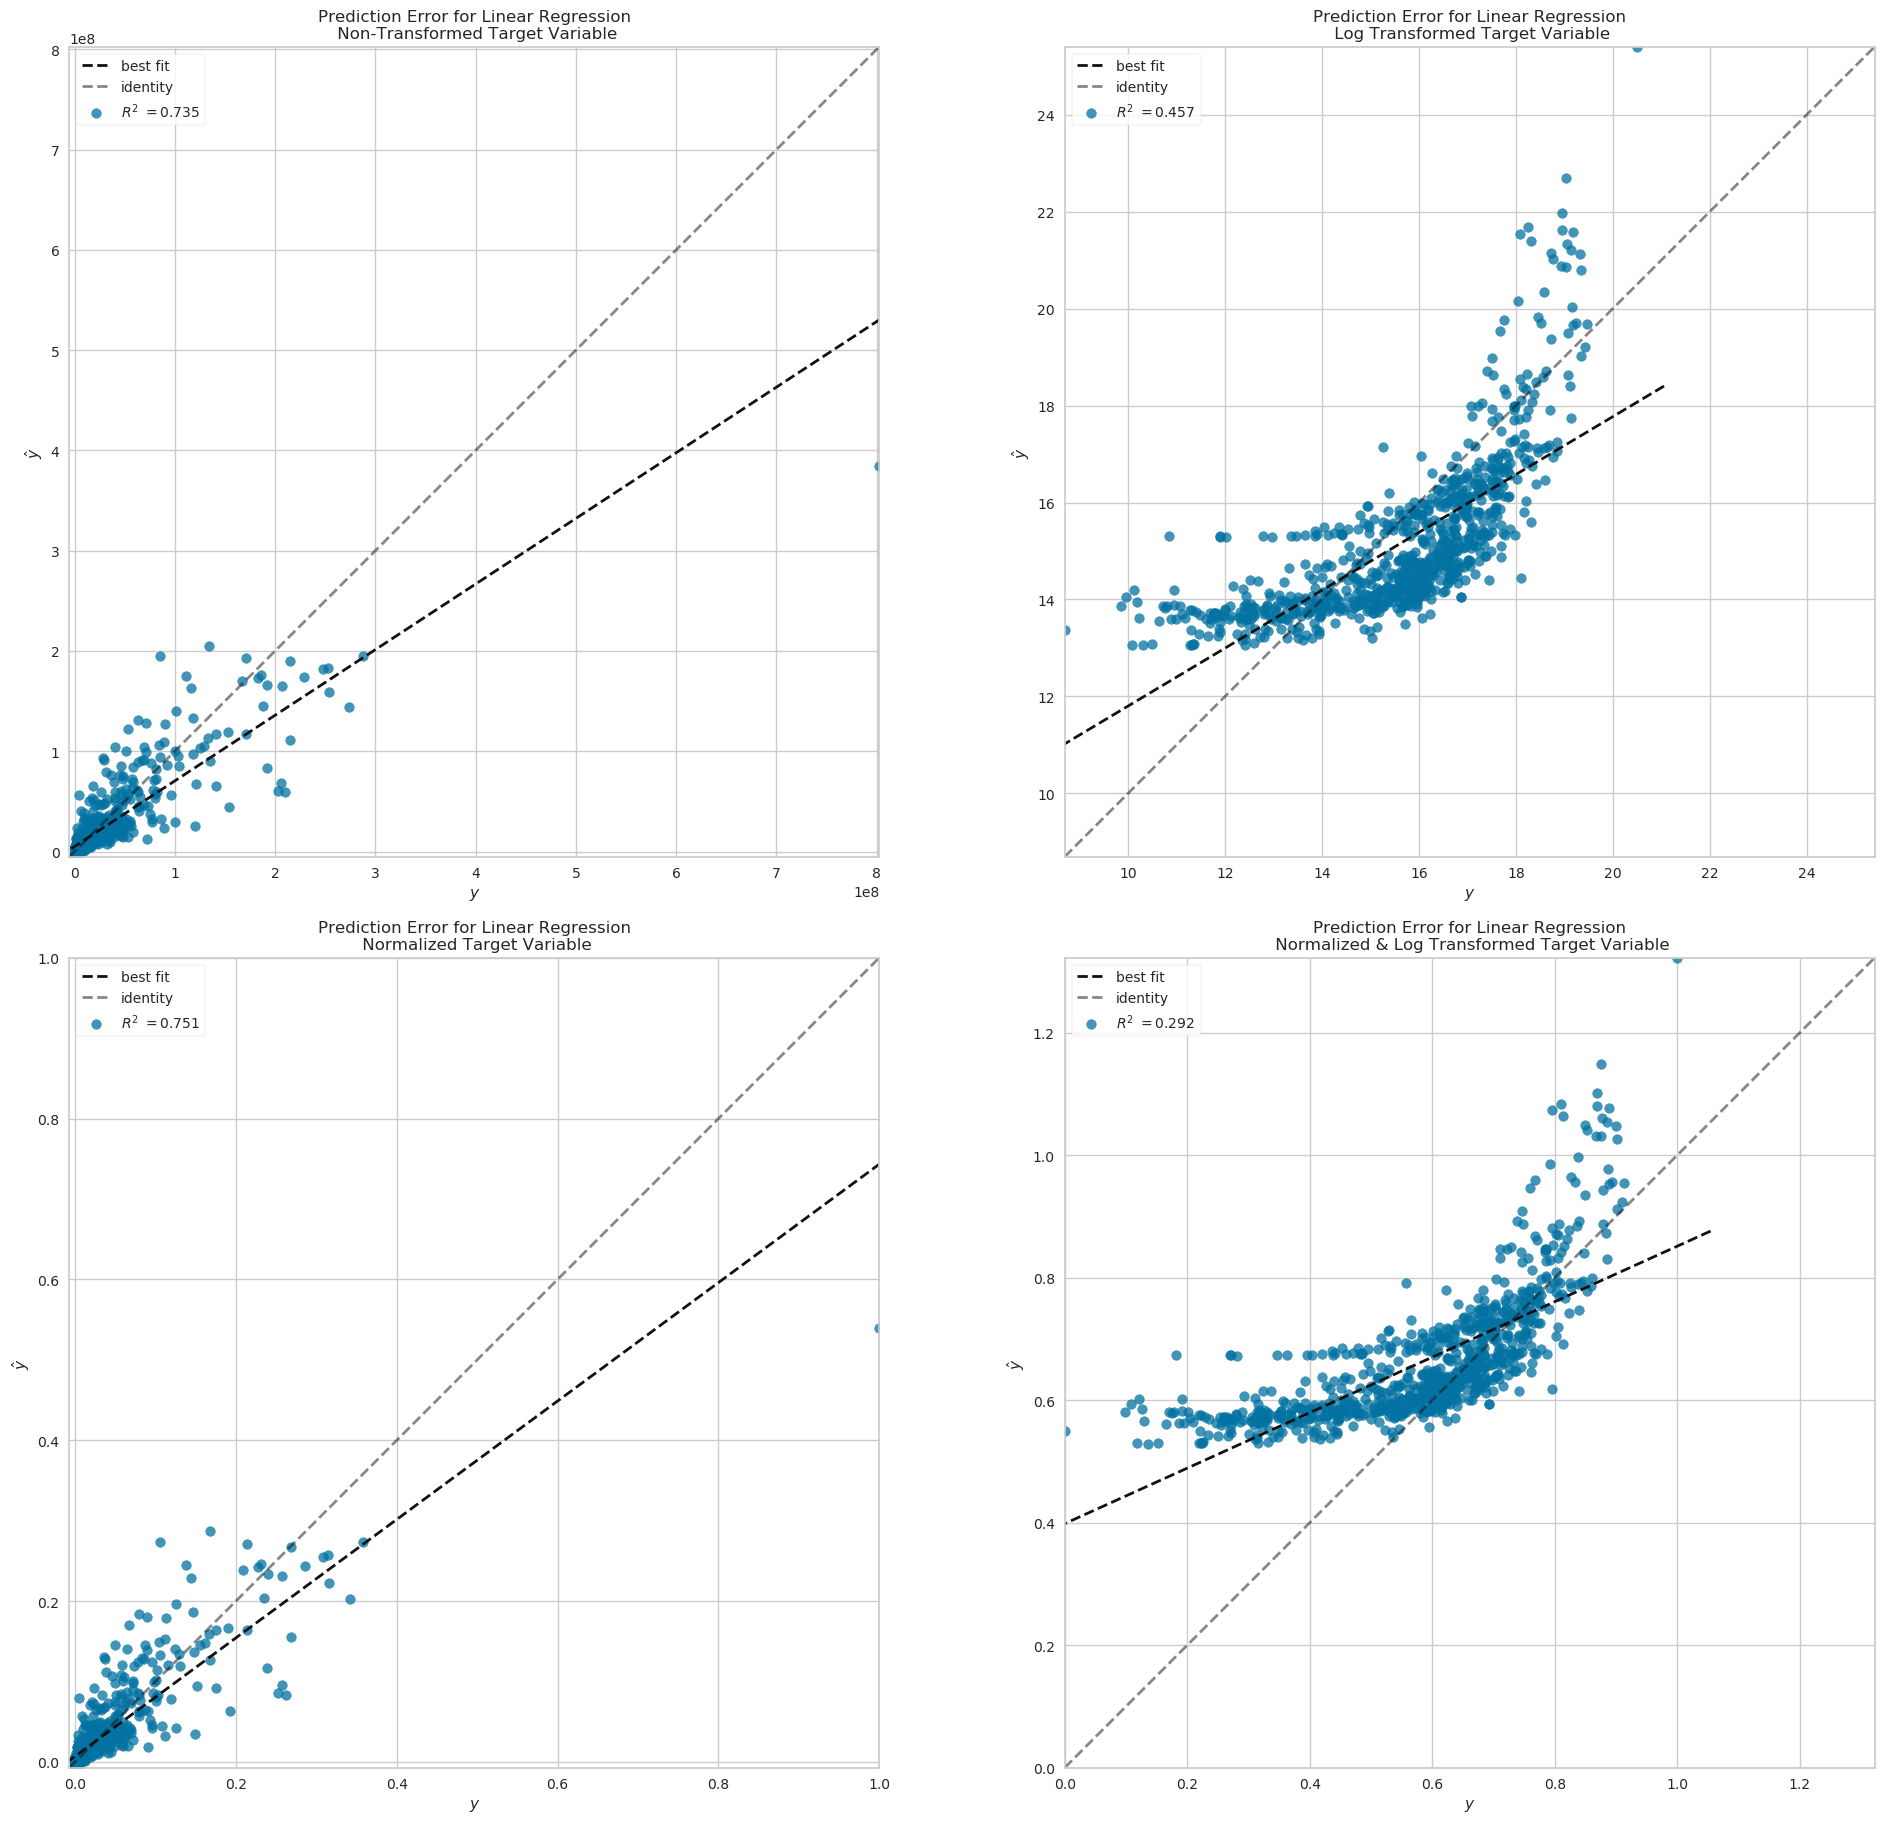

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()

model = LinearRegression(fit_intercept=True, n_jobs=-1)
visualizer0 = PredictionError(model, ax=axes[0])
visualizer0.fit(X_train[automatic_selected_features], y_train)
visualizer0.score(X_test[automatic_selected_features], y_test)
visualizer0.finalize()
axes[0].set_title('Prediction Error for Linear Regression\n Non-Transformed Target Variable')

model = LinearRegression(fit_intercept=True, n_jobs=-1)
visualizer1 = PredictionError(model, ax=axes[1])
visualizer1.fit(X_train[automatic_selected_features], y_train_log)
visualizer1.score(X_test[automatic_selected_features], y_test_log)
visualizer1.finalize()
axes[1].set_title('Prediction Error for Linear Regression\n Log Transformed Target Variable')


model = LinearRegression(fit_intercept=True, n_jobs=-1)
visualizer2 = PredictionError(model, ax=axes[2])
visualizer2.fit(X_train[automatic_selected_features], y_train_normalized)
visualizer2.score(X_test[automatic_selected_features], y_test_normalized)
visualizer2.finalize()
axes[2].set_title('Prediction Error for Linear Regression\n Normalized Target Variable')

model = LinearRegression(fit_intercept=True, n_jobs=-1)
visualizer3 = PredictionError(model, ax=axes[3])
visualizer3.fit(X_train[automatic_selected_features], y_train_log_normalized)
visualizer3.score(X_test[automatic_selected_features], y_test_log_normalized)
visualizer3.finalize()
axes[3].set_title('Prediction Error for Linear Regression\n Normalized & Log Transformed Target Variable')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../images/residuals_automaticfeatures_linearregression.png', dpi=300)

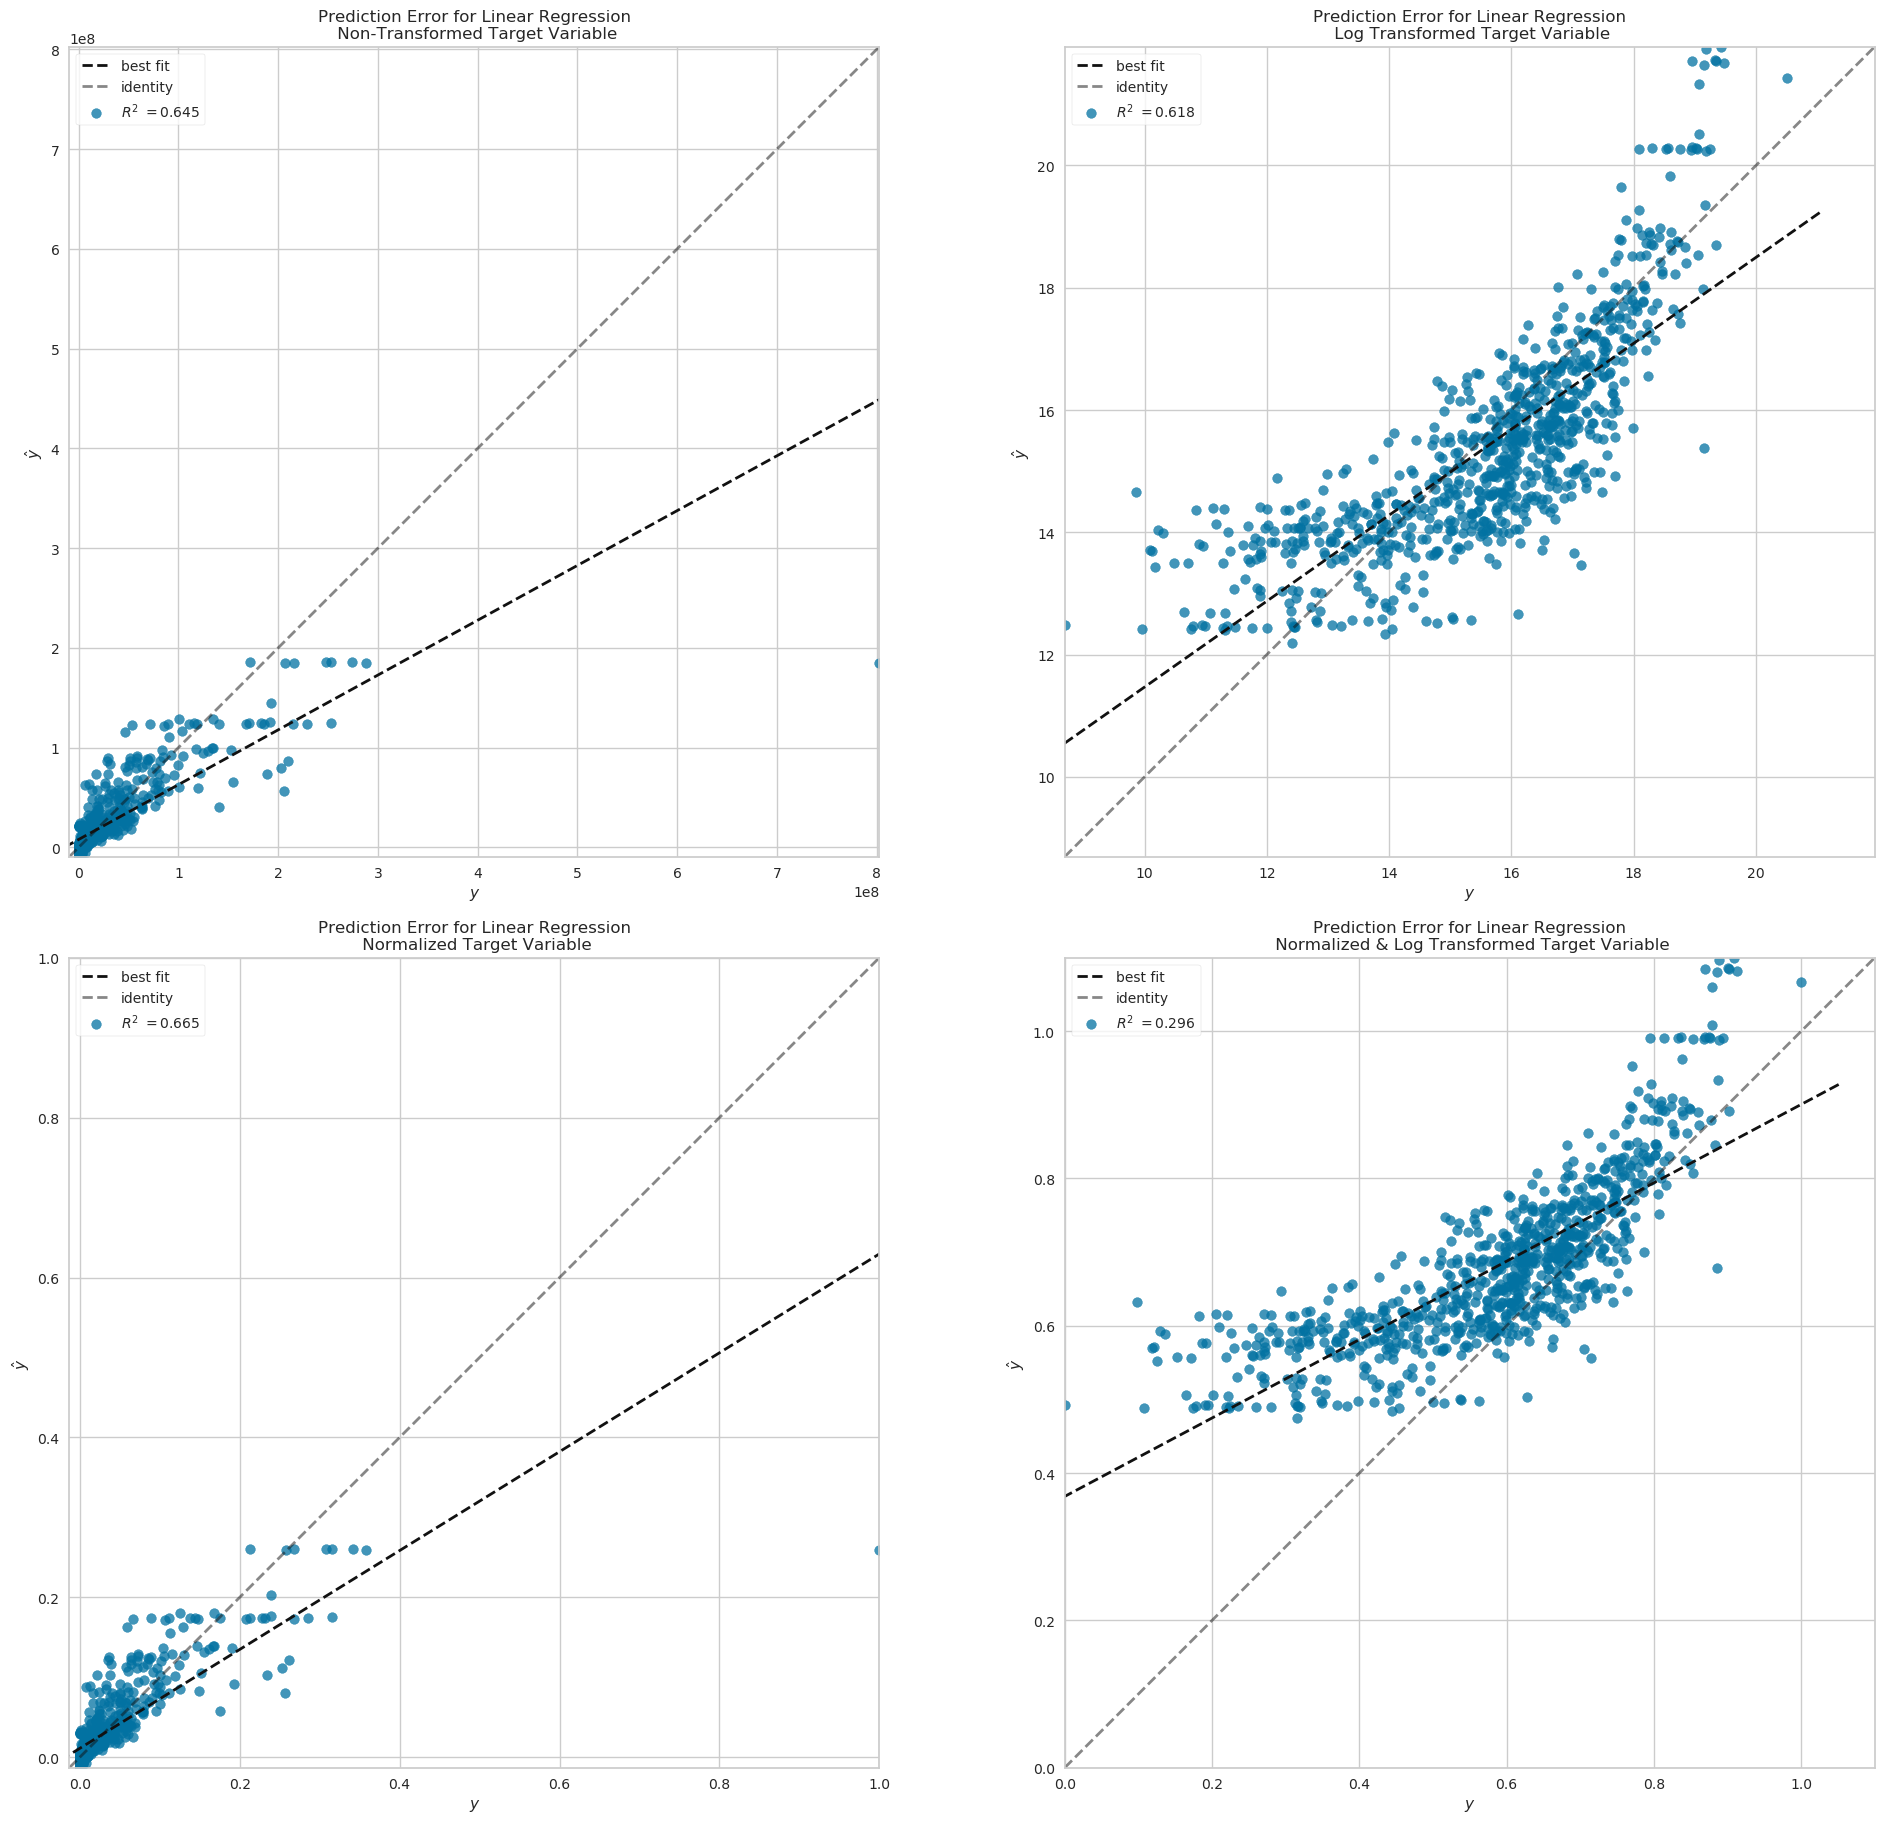

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()

model = LinearRegression(fit_intercept=True, n_jobs=-1)
visualizer0 = PredictionError(model, ax=axes[0])
visualizer0.fit(X_train[other_features], y_train)
visualizer0.score(X_test[other_features], y_test)
visualizer0.finalize()
axes[0].set_title('Prediction Error for Linear Regression\n Non-Transformed Target Variable')

model = LinearRegression(fit_intercept=True, n_jobs=-1)
visualizer1 = PredictionError(model, ax=axes[1])
visualizer1.fit(X_train[other_features], y_train_log)
visualizer1.score(X_test[other_features], y_test_log)
visualizer1.finalize()
axes[1].set_title('Prediction Error for Linear Regression\n Log Transformed Target Variable')


model = LinearRegression(fit_intercept=True, n_jobs=-1)
visualizer2 = PredictionError(model, ax=axes[2])
visualizer2.fit(X_train[other_features], y_train_normalized)
visualizer2.score(X_test[other_features], y_test_normalized)
visualizer2.finalize()
axes[2].set_title('Prediction Error for Linear Regression\n Normalized Target Variable')

model = LinearRegression(fit_intercept=True, n_jobs=-1)
visualizer3 = PredictionError(model, ax=axes[3])
visualizer3.fit(X_train[other_features], y_train_log_normalized)
visualizer3.score(X_test[other_features], y_test_log_normalized)
visualizer3.finalize()
axes[3].set_title('Prediction Error for Linear Regression\n Normalized & Log Transformed Target Variable')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../images/residuals_otherfeatures_linearregression.png', dpi=300)

### **Random Forest Regression**

In [10]:
def random_forest_regressor_gridsearch(features, target, scoring_metric):
    
    logo = LeaveOneGroupOut()
    random_forest_regressor = RandomForestRegressor(n_jobs=-1, random_state=42)

    parameters = {
        'n_estimators':list(range(80, 200, 20)),
        #'criterion':['squared_error', 'absolute_error', 'friedman_mse', 'poisson'],
        'max_depth':list(range(2,10,2)),
        #'min_samples_split':list(range(2,10,2)),
        #'min_samples_leaf':list(range(1,5)),
        #'max_features':['sqrt', 'log2']    
    }

    random_forest_regressor_gridsearch = GridSearchCV(random_forest_regressor, parameters, scoring=scoring_metric, cv=logo, n_jobs=-1)
    random_forest_regressor_gridsearch.fit(X[features], y=target, groups=divisions)
    print("Best parameters of the random forest regressor are: %s" % random_forest_regressor_gridsearch.best_params_)
    print("Best score with the best parameters is: %s" % random_forest_regressor_gridsearch.best_score_)
    print("Average score is: %s\n" % random_forest_regressor_gridsearch.cv_results_["mean_test_score"].mean())
    
    return random_forest_regressor_gridsearch.best_params_ 


def random_forest_regressor_crossvalidation(features, target, target_train, target_test, scoring_metric, params):

    logo = LeaveOneGroupOut()
    logo_cv = logo.split(X[features], target, groups=divisions)
    random_forest_regressor = RandomForestRegressor(max_depth=params['max_depth'], n_estimators=params['n_estimators'], n_jobs=-1, random_state=42)

    y_predict1 = cross_val_predict(random_forest_regressor, X[features], target, groups=divisions, cv=logo_cv, n_jobs=-1)
    scores = cross_validate(random_forest_regressor, X[features], target, groups=divisions, cv=logo, scoring=scoring_metric, return_estimator=True)
    
    random_forest_regressor.fit(X_train[features], target_train)
    y_predict2 = random_forest_regressor.predict(X_test[features])
    
    if scoring_metric is 'r2':
        print('CrossValPredict R2 is %s' % r2_score(target, y_predict1))
        print('TrainTestSplit R2 is %s' % r2_score(target_test, y_predict2))
        print('Average R2 is %s' % scores['test_score'].mean())
        print('Best R2 is %s\n' % scores['test_score'].max())
    elif scoring_metric is 'neg_mean_squared_log_error':
        print('CrossValPredict MSLE is %s' % mean_squared_log_error(target, y_predict1))
        print('TrainTestSplit MSLE is %s' % mean_squared_log_error(target_test, y_predict2))
        print('Average MSLE is %s' % scores['test_score'].mean())
        print('Best MSLE is %s\n' % scores['test_score'].max())
        
    return scores['test_score'].mean()

In [11]:
params0 = random_forest_regressor_gridsearch(automatic_selected_features, y, 'neg_mean_squared_log_error')
params1 = random_forest_regressor_gridsearch(automatic_selected_features, y_normalized, 'neg_mean_squared_log_error')
params2 = random_forest_regressor_gridsearch(automatic_selected_features, y_log, 'neg_mean_squared_log_error')
params3 = random_forest_regressor_gridsearch(automatic_selected_features, y_log_normalized, 'neg_mean_squared_log_error')

print('\n')

average_score_automaticfeatures_nontransformed_rf = random_forest_regressor_crossvalidation(automatic_selected_features, y, y_train, y_test, 'neg_mean_squared_log_error', params0)
average_score_automaticfeatures_normalized_rf = random_forest_regressor_crossvalidation(automatic_selected_features, y_normalized, y_train_normalized, y_test_normalized, 'neg_mean_squared_log_error', params1)
average_score_automaticfeatures_log_rf = random_forest_regressor_crossvalidation(automatic_selected_features, y_log, y_train_log, y_test_log, 'neg_mean_squared_log_error', params2)
average_score_automaticfeatures_log_normalized_rf = random_forest_regressor_crossvalidation(automatic_selected_features, y_log_normalized, y_train_log_normalized, y_test_log_normalized, 'neg_mean_squared_log_error', params3)

Best parameters of the random forest regressor are: {'max_depth': 8, 'n_estimators': 180}
Best score with the best parameters is: -0.7696649092023732
Average score is: -1.8178239175213815

Best parameters of the random forest regressor are: {'max_depth': 8, 'n_estimators': 120}
Best score with the best parameters is: -0.00033206842639902983
Average score is: -0.0004225437206297673

Best parameters of the random forest regressor are: {'max_depth': 8, 'n_estimators': 120}
Best score with the best parameters is: -0.0030311115533740367
Average score is: -0.0037752722513942857

Best parameters of the random forest regressor are: {'max_depth': 8, 'n_estimators': 120}
Best score with the best parameters is: -0.0010014777023481995
Average score is: -0.0012719315985548919



CrossValPredict MSLE is 0.7353862456225262
TrainTestSplit MSLE is 0.421424962394168
Average MSLE is -0.7696649092023732
Best MSLE is -0.421424962394168

CrossValPredict MSLE is 0.0003472834158608199
TrainTestSplit MSLE is 0

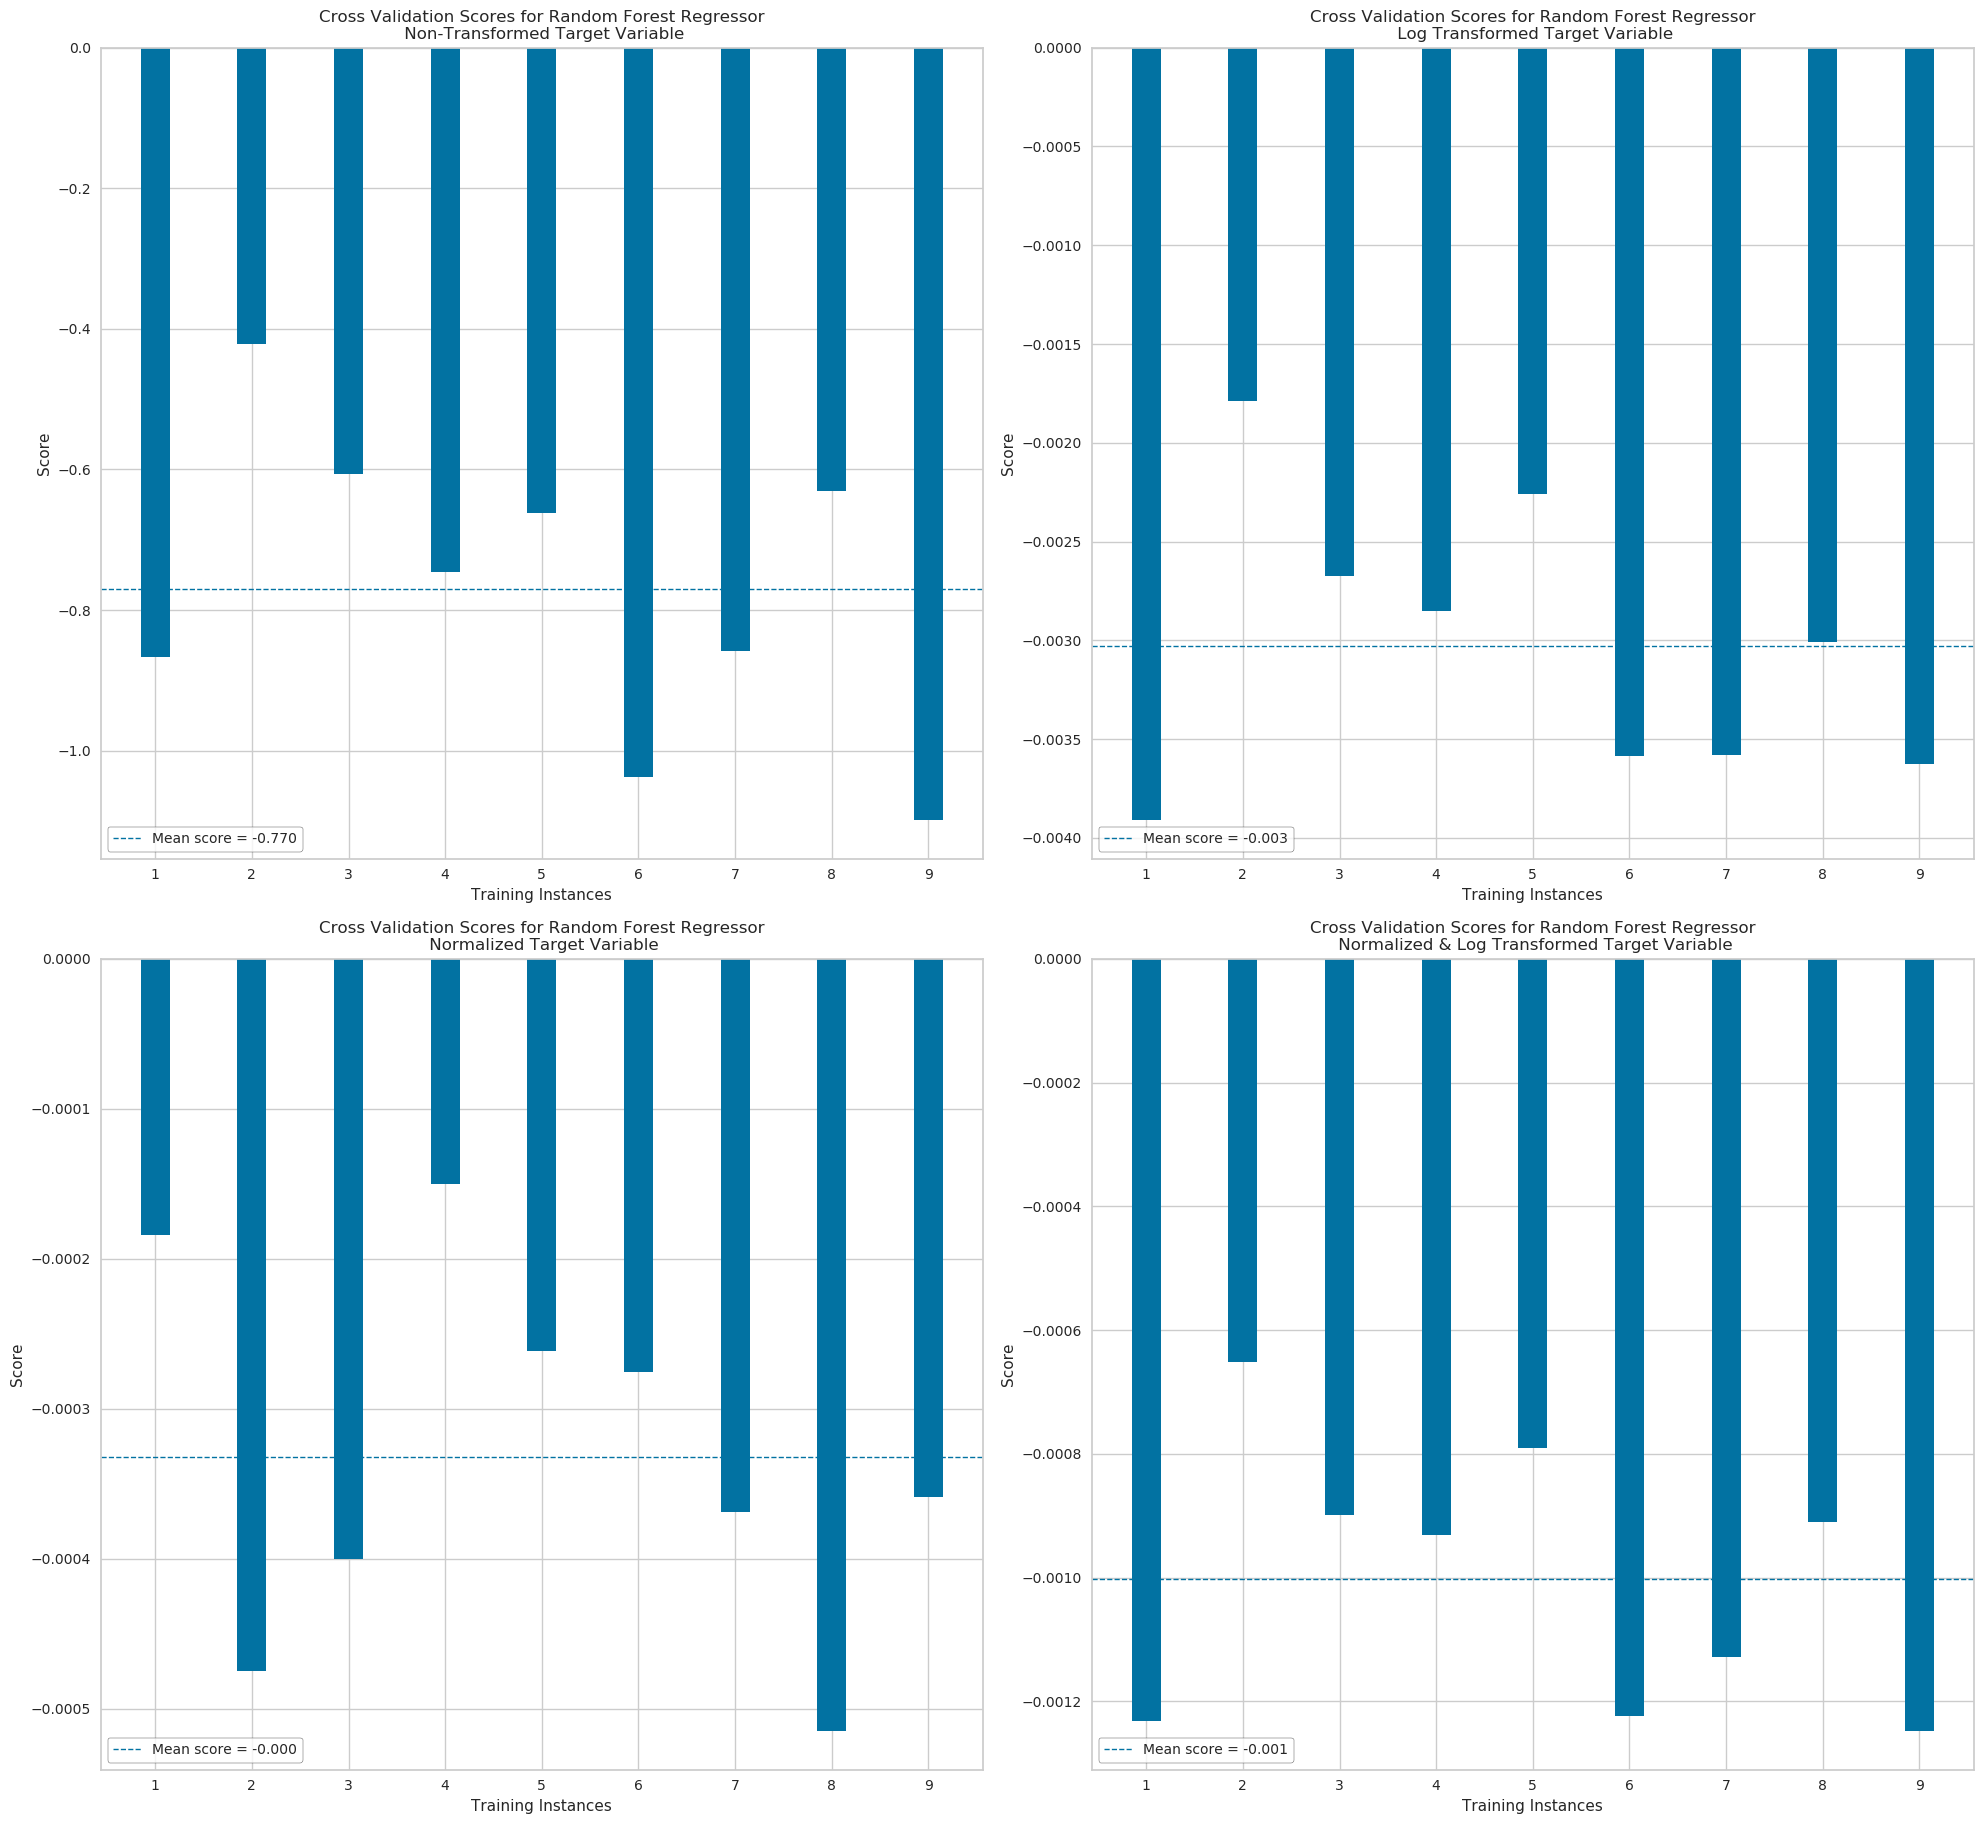

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y, groups=divisions)
model = RandomForestRegressor(max_depth=params0['max_depth'], n_estimators=params0['n_estimators'], n_jobs=-1, random_state=42)
visualizer0 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[0])
visualizer0.fit(X[automatic_selected_features], y)
visualizer0.finalize()
axes[0].set_title('Cross Validation Scores for Random Forest Regressor\n Non-Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_log, groups=divisions)
model = RandomForestRegressor(max_depth=params1['max_depth'], n_estimators=params1['n_estimators'], n_jobs=-1, random_state=42)
visualizer1 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[1])
visualizer1.fit(X[automatic_selected_features], y_log)
visualizer1.finalize()
axes[1].set_title('Cross Validation Scores for Random Forest Regressor\n Log Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_normalized, groups=divisions)
model = RandomForestRegressor(max_depth=params2['max_depth'], n_estimators=params2['n_estimators'], n_jobs=-1, random_state=42)
visualizer2 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[2])
visualizer2.fit(X[automatic_selected_features], y_normalized)
visualizer2.finalize()
axes[2].set_title('Cross Validation Scores for Random Forest Regressor\n Normalized Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_log_normalized, groups=divisions)
model = RandomForestRegressor(max_depth=params3['max_depth'], n_estimators=params3['n_estimators'], n_jobs=-1, random_state=42)
visualizer3 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[3])
visualizer3.fit(X[automatic_selected_features], y_log_normalized)
visualizer3.finalize()
axes[3].set_title('Cross Validation Scores for Random Forest Regressor\n Normalized & Log Transformed Target Variable')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../images/crossvalidationscores_automaticfeatures_randomforest.png', dpi=300)

In [13]:
params0 = random_forest_regressor_gridsearch(other_features, y, 'neg_mean_squared_log_error')
params1 = random_forest_regressor_gridsearch(other_features, y_normalized, 'neg_mean_squared_log_error')
params2 = random_forest_regressor_gridsearch(other_features, y_log, 'neg_mean_squared_log_error')
params3 = random_forest_regressor_gridsearch(other_features, y_log_normalized, 'neg_mean_squared_log_error')

print('\n')

average_score_otherfeatures_nontransformed_rf = random_forest_regressor_crossvalidation(other_features, y, y_train, y_test, 'neg_mean_squared_log_error', params0)
average_score_otherfeatures_normalized_rf = random_forest_regressor_crossvalidation(other_features, y_normalized, y_train_normalized, y_test_normalized, 'neg_mean_squared_log_error', params1)
average_score_otherfeatures_log_rf = random_forest_regressor_crossvalidation(other_features, y_log, y_train_log, y_test_log, 'neg_mean_squared_log_error', params2)
average_score_otherfeatures_log_normalized_rf = random_forest_regressor_crossvalidation(other_features, y_log_normalized, y_train_log_normalized, y_test_log_normalized, 'neg_mean_squared_log_error', params3)

Best parameters of the random forest regressor are: {'max_depth': 8, 'n_estimators': 180}
Best score with the best parameters is: -0.7659282746996627
Average score is: -1.7739324685656044

Best parameters of the random forest regressor are: {'max_depth': 6, 'n_estimators': 120}
Best score with the best parameters is: -0.0004788278612505612
Average score is: -0.0005251075775892466

Best parameters of the random forest regressor are: {'max_depth': 8, 'n_estimators': 180}
Best score with the best parameters is: -0.0031461678876338766
Average score is: -0.0038653315644175414

Best parameters of the random forest regressor are: {'max_depth': 8, 'n_estimators': 180}
Best score with the best parameters is: -0.0010425673724851277
Average score is: -0.0013030532170529216



CrossValPredict MSLE is 0.727344023976246
TrainTestSplit MSLE is 0.41850570107436685
Average MSLE is -0.7659282746996628
Best MSLE is -0.41850570107436685

CrossValPredict MSLE is 0.0005055078695933013
TrainTestSplit MSLE is

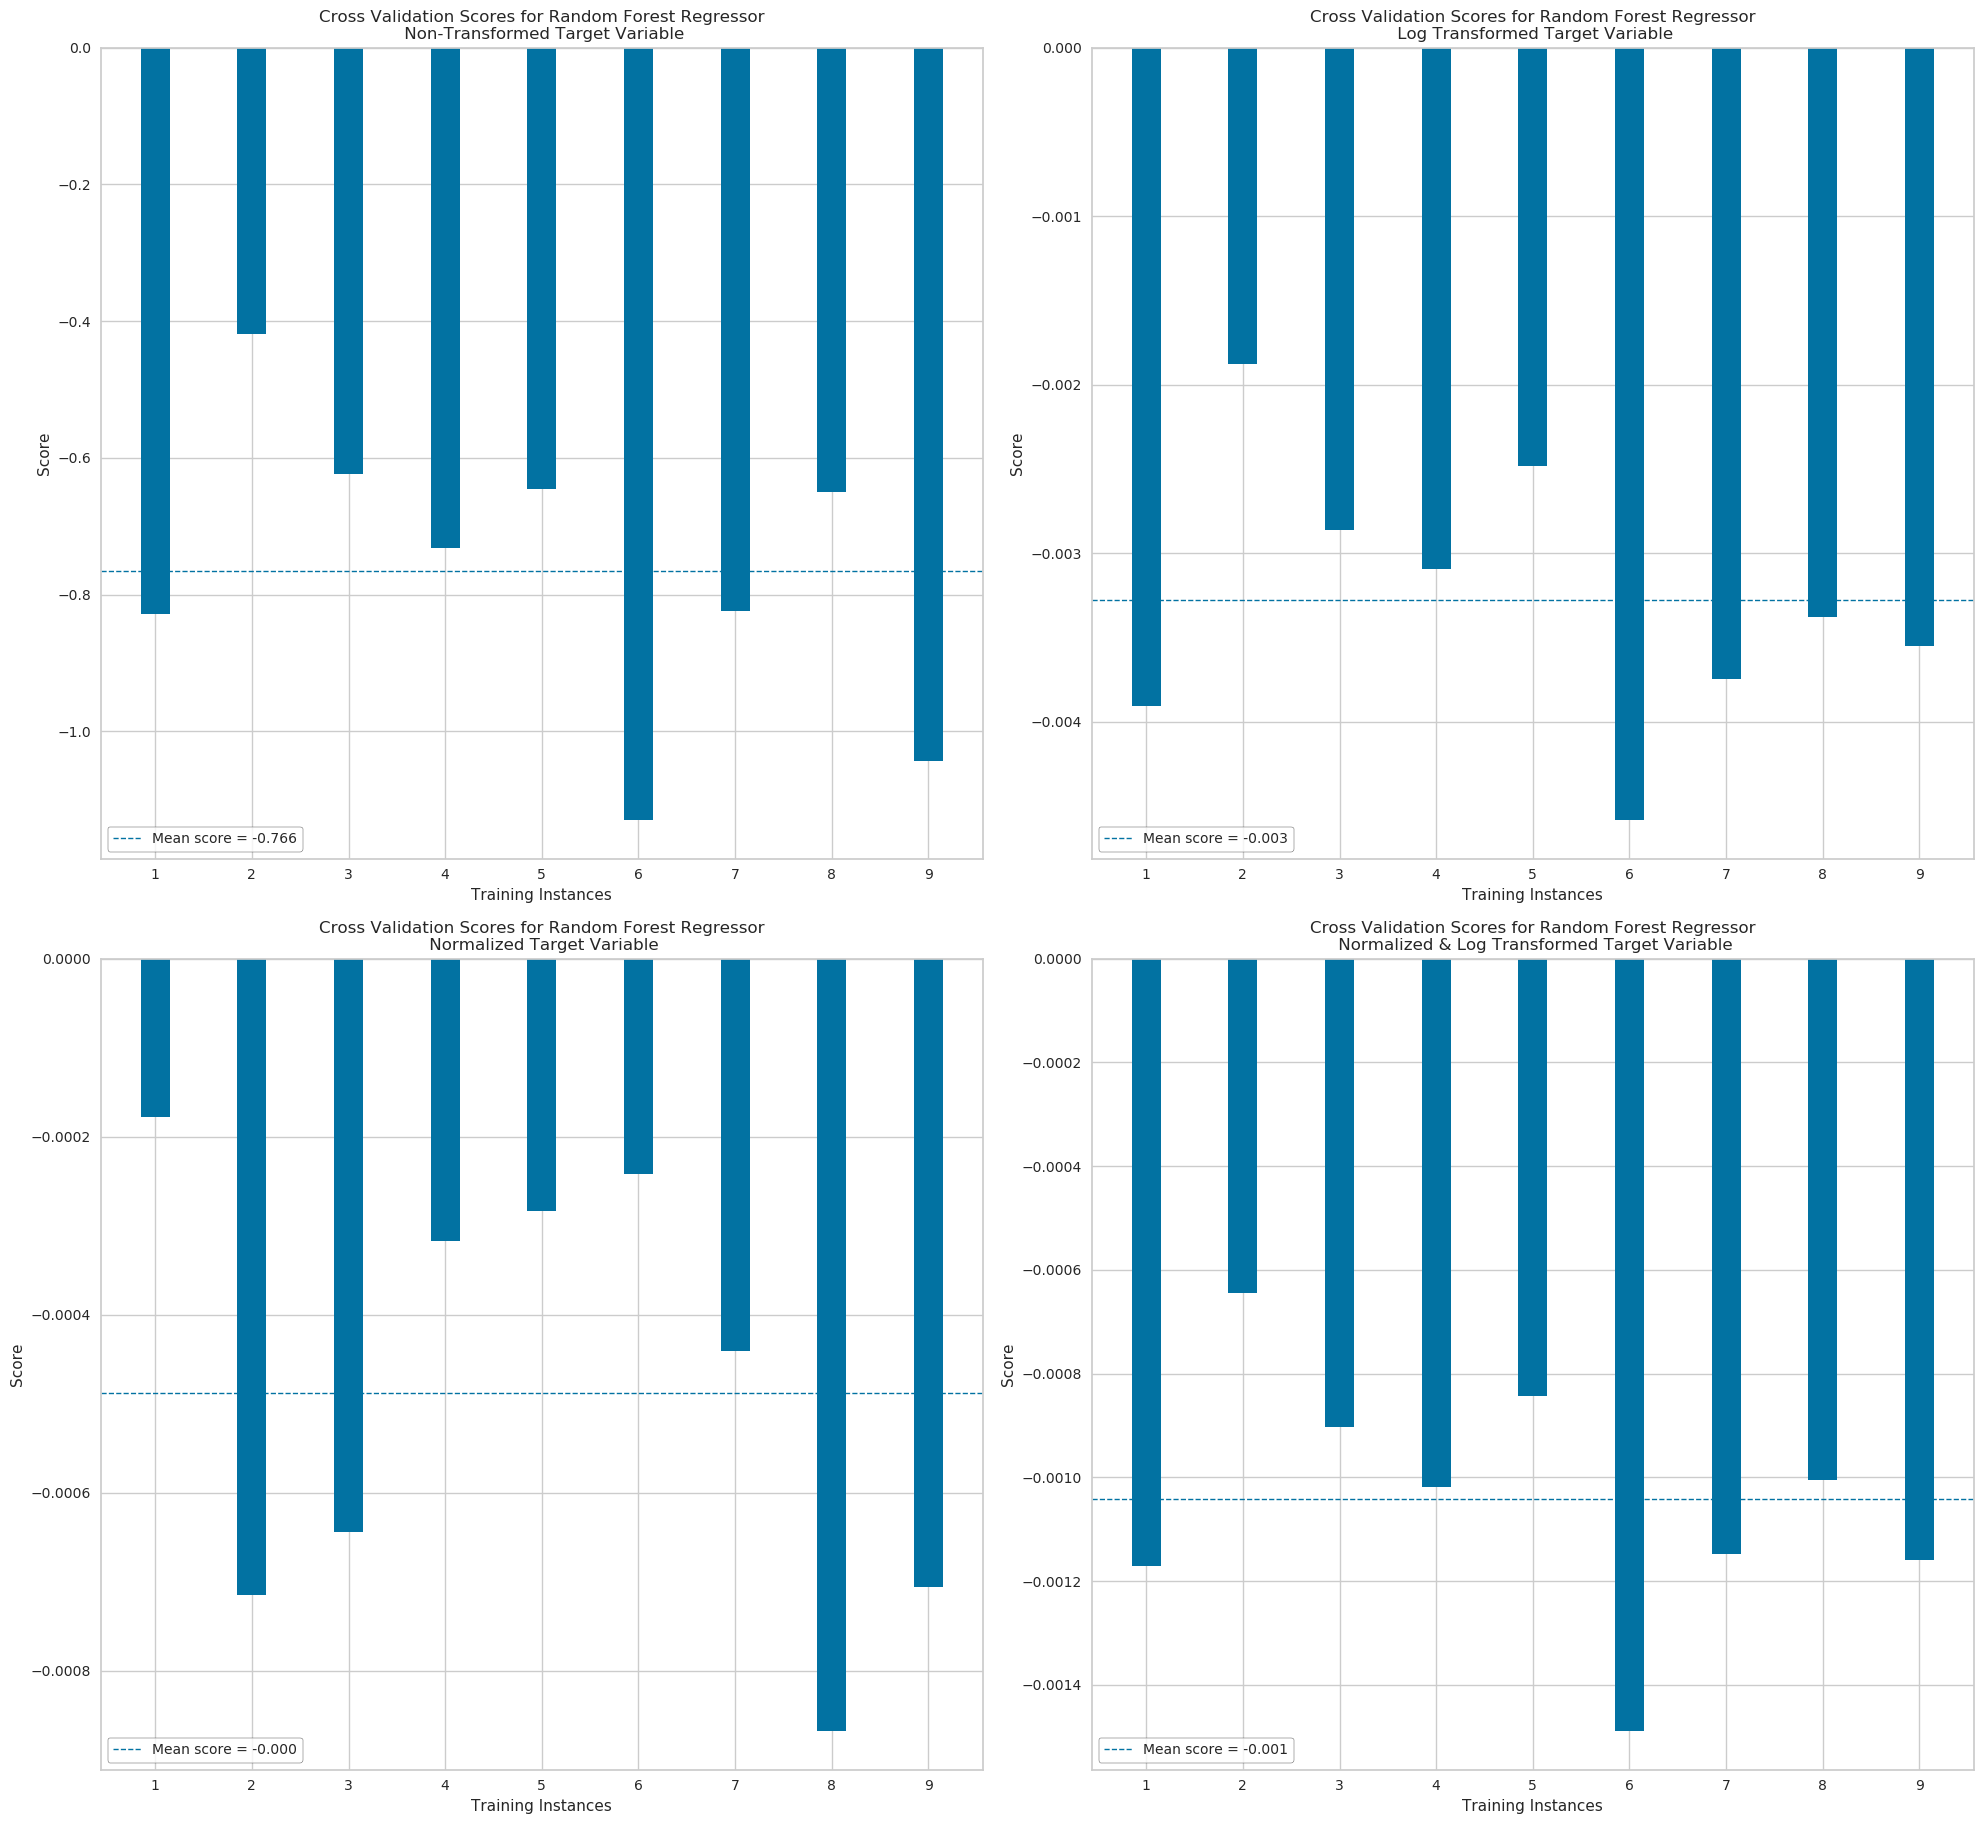

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y, groups=divisions)
model = RandomForestRegressor(max_depth=params0['max_depth'], n_estimators=params0['n_estimators'], n_jobs=-1, random_state=42)
visualizer0 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[0])
visualizer0.fit(X[other_features], y)
visualizer0.finalize()
axes[0].set_title('Cross Validation Scores for Random Forest Regressor\n Non-Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_log, groups=divisions)
model = RandomForestRegressor(max_depth=params1['max_depth'], n_estimators=params1['n_estimators'], n_jobs=-1, random_state=42)
visualizer1 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[1])
visualizer1.fit(X[other_features], y_log)
visualizer1.finalize()
axes[1].set_title('Cross Validation Scores for Random Forest Regressor\n Log Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_normalized, groups=divisions)
model = RandomForestRegressor(max_depth=params2['max_depth'], n_estimators=params2['n_estimators'], n_jobs=-1, random_state=42)
visualizer2 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[2])
visualizer2.fit(X[other_features], y_normalized)
visualizer2.finalize()
axes[2].set_title('Cross Validation Scores for Random Forest Regressor\n Normalized Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_log_normalized, groups=divisions)
model = RandomForestRegressor(max_depth=params3['max_depth'], n_estimators=params3['n_estimators'], n_jobs=-1, random_state=42)
visualizer3 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[3])
visualizer3.fit(X[other_features], y_log_normalized)
visualizer3.finalize()
axes[3].set_title('Cross Validation Scores for Random Forest Regressor\n Normalized & Log Transformed Target Variable')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../images/crossvalidationscores_otherfeatures_randomforest.png', dpi=300)

In [15]:
print(pd.DataFrame(list(zip(['Non Transformed Target', 'Normalized Target', 'Log Transformation', 'Normalized Log Transformation'], 
                   [average_score_automaticfeatures_nontransformed_rf * -1, average_score_automaticfeatures_normalized_rf * -1,
                    average_score_automaticfeatures_log_rf * -1, average_score_automaticfeatures_log_normalized_rf * -1],
                   [average_score_otherfeatures_nontransformed_rf * -1, average_score_otherfeatures_normalized_rf * -1,
                    average_score_otherfeatures_log_rf * -1, average_score_otherfeatures_log_normalized_rf * -1])),
                   columns=['Transformation of Target Variable', 'Cross Validated Average MSLE for Automatically Selected Features',
                            'Cross Validated Average MSLE for Other Selected Features']).to_latex(index=False))

\begin{tabular}{lrr}
\toprule
Transformation of Target Variable &  Cross Validated Average MSLE for Automatically Selected Features &  Cross Validated Average MSLE for Other Selected Features \\
\midrule
           Non Transformed Target &                                           0.769665 &                                           0.765928 \\
                Normalized Target &                                           0.000332 &                                           0.000479 \\
               Log Transformation &                                           0.003031 &                                           0.003146 \\
    Normalized Log Transformation &                                           0.001001 &                                           0.001043 \\
\bottomrule
\end{tabular}



### **K-Nearest Neighbors Regression**

In [16]:
def knn_regressor_gridsearch(features, target, scoring_metric):
    
    logo = LeaveOneGroupOut()
    knn_regressor = KNeighborsRegressor(n_jobs=-1)

    parameters = {
        'n_neighbors':list(range(3,10,1)),
        'weights':['uniform', 'distance'],
        'algorithm':['auto', 'ball_tree', 'kd_tree'],
        'leaf_size':list(range(20, 40, 5))
    }

    knn_regressor_gridsearch = GridSearchCV(knn_regressor, parameters, scoring='neg_mean_squared_log_error', cv=logo, n_jobs=-1)
    knn_regressor_gridsearch.fit(X[features], y=target, groups=divisions)
    print("Best parameters of the k-nearest neighbors regressor are: %s" % knn_regressor_gridsearch.best_params_)
    print("Best score with the best parameters is: %.5s" % knn_regressor_gridsearch.best_score_)
    print("Average score is: %.5s \n" % knn_regressor_gridsearch.cv_results_["mean_test_score"].mean())
    
    return knn_regressor_gridsearch.best_params_



def knn_regressor_crossvalidation(features, target, target_train, target_test, scoring_metric, params):
    
    logo = LeaveOneGroupOut()
    logo_cv = logo.split(X[features], target, groups=divisions)
    knn_regressor = KNeighborsRegressor(algorithm=params['algorithm'], leaf_size=params['leaf_size'], n_neighbors=params['n_neighbors'], weights=params['weights'], n_jobs=-1)

    y_predict1 = cross_val_predict(knn_regressor, X[features], target, groups=divisions, cv=logo_cv, n_jobs=-1)
    scores = cross_validate(knn_regressor, X[features], target, groups=divisions, cv=logo, scoring=scoring_metric, return_estimator=True)
    
    knn_regressor.fit(X_train[features], target_train)
    y_predict2 = knn_regressor.predict(X_test[features])
    
    if scoring_metric is 'r2':
        print('CrossValPredict R2 is %s' % r2_score(target, y_predict1))
        print('TrainTestSplit R2 is %s' % r2_score(target_test, y_predict2))
        print('Average R2 is %s' % scores['test_score'].mean())
        print('Best R2 is %s\n' % scores['test_score'].max())
    elif scoring_metric is 'neg_mean_squared_log_error':
        print('CrossValPredict MSLE is %s' % mean_squared_log_error(target, y_predict1))
        print('TrainTestSplit MSLE is %s' % mean_squared_log_error(target_test, y_predict2))
        print('Average MSLE is %s' % scores['test_score'].mean())
        print('Best MSLE is %s\n' % scores['test_score'].max())

    return scores['test_score'].mean()

In [17]:
params0 = knn_regressor_gridsearch(automatic_selected_features, y, 'neg_mean_squared_log_error')
params1 = knn_regressor_gridsearch(automatic_selected_features, y_normalized, 'neg_mean_squared_log_error')
params2 = knn_regressor_gridsearch(automatic_selected_features, y_log, 'neg_mean_squared_log_error')
params3 = knn_regressor_gridsearch(automatic_selected_features, y_log_normalized, 'neg_mean_squared_log_error')

print('\n')

average_score_automaticfeatures_nontransformed_knn = knn_regressor_crossvalidation(automatic_selected_features, y, y_train, y_test, 'neg_mean_squared_log_error', params0)
average_score_automaticfeatures_normalized_knn = knn_regressor_crossvalidation(automatic_selected_features, y_normalized, y_train_normalized, y_test_normalized, 'neg_mean_squared_log_error', params1)
average_score_automaticfeatures_log_knn = knn_regressor_crossvalidation(automatic_selected_features, y_log, y_train_log, y_test_log, 'neg_mean_squared_log_error', params2)
average_score_automaticfeatures_log_normalized_knn = knn_regressor_crossvalidation(automatic_selected_features, y_log_normalized, y_train_log_normalized, y_test_log_normalized, 'neg_mean_squared_log_error', params3)    

Best parameters of the k-nearest neighbors regressor are: {'algorithm': 'ball_tree', 'leaf_size': 25, 'n_neighbors': 9, 'weights': 'uniform'}
Best score with the best parameters is: -0.71
Average score is: -0.73 

Best parameters of the k-nearest neighbors regressor are: {'algorithm': 'ball_tree', 'leaf_size': 20, 'n_neighbors': 5, 'weights': 'distance'}
Best score with the best parameters is: -0.00
Average score is: -0.00 

Best parameters of the k-nearest neighbors regressor are: {'algorithm': 'ball_tree', 'leaf_size': 20, 'n_neighbors': 9, 'weights': 'uniform'}
Best score with the best parameters is: -0.00
Average score is: -0.00 

Best parameters of the k-nearest neighbors regressor are: {'algorithm': 'ball_tree', 'leaf_size': 20, 'n_neighbors': 9, 'weights': 'uniform'}
Best score with the best parameters is: -0.00
Average score is: -0.00 



CrossValPredict MSLE is 0.6818053035960231
TrainTestSplit MSLE is 0.49777699651869656
Average MSLE is -0.714011116254793
Best MSLE is -0.4977

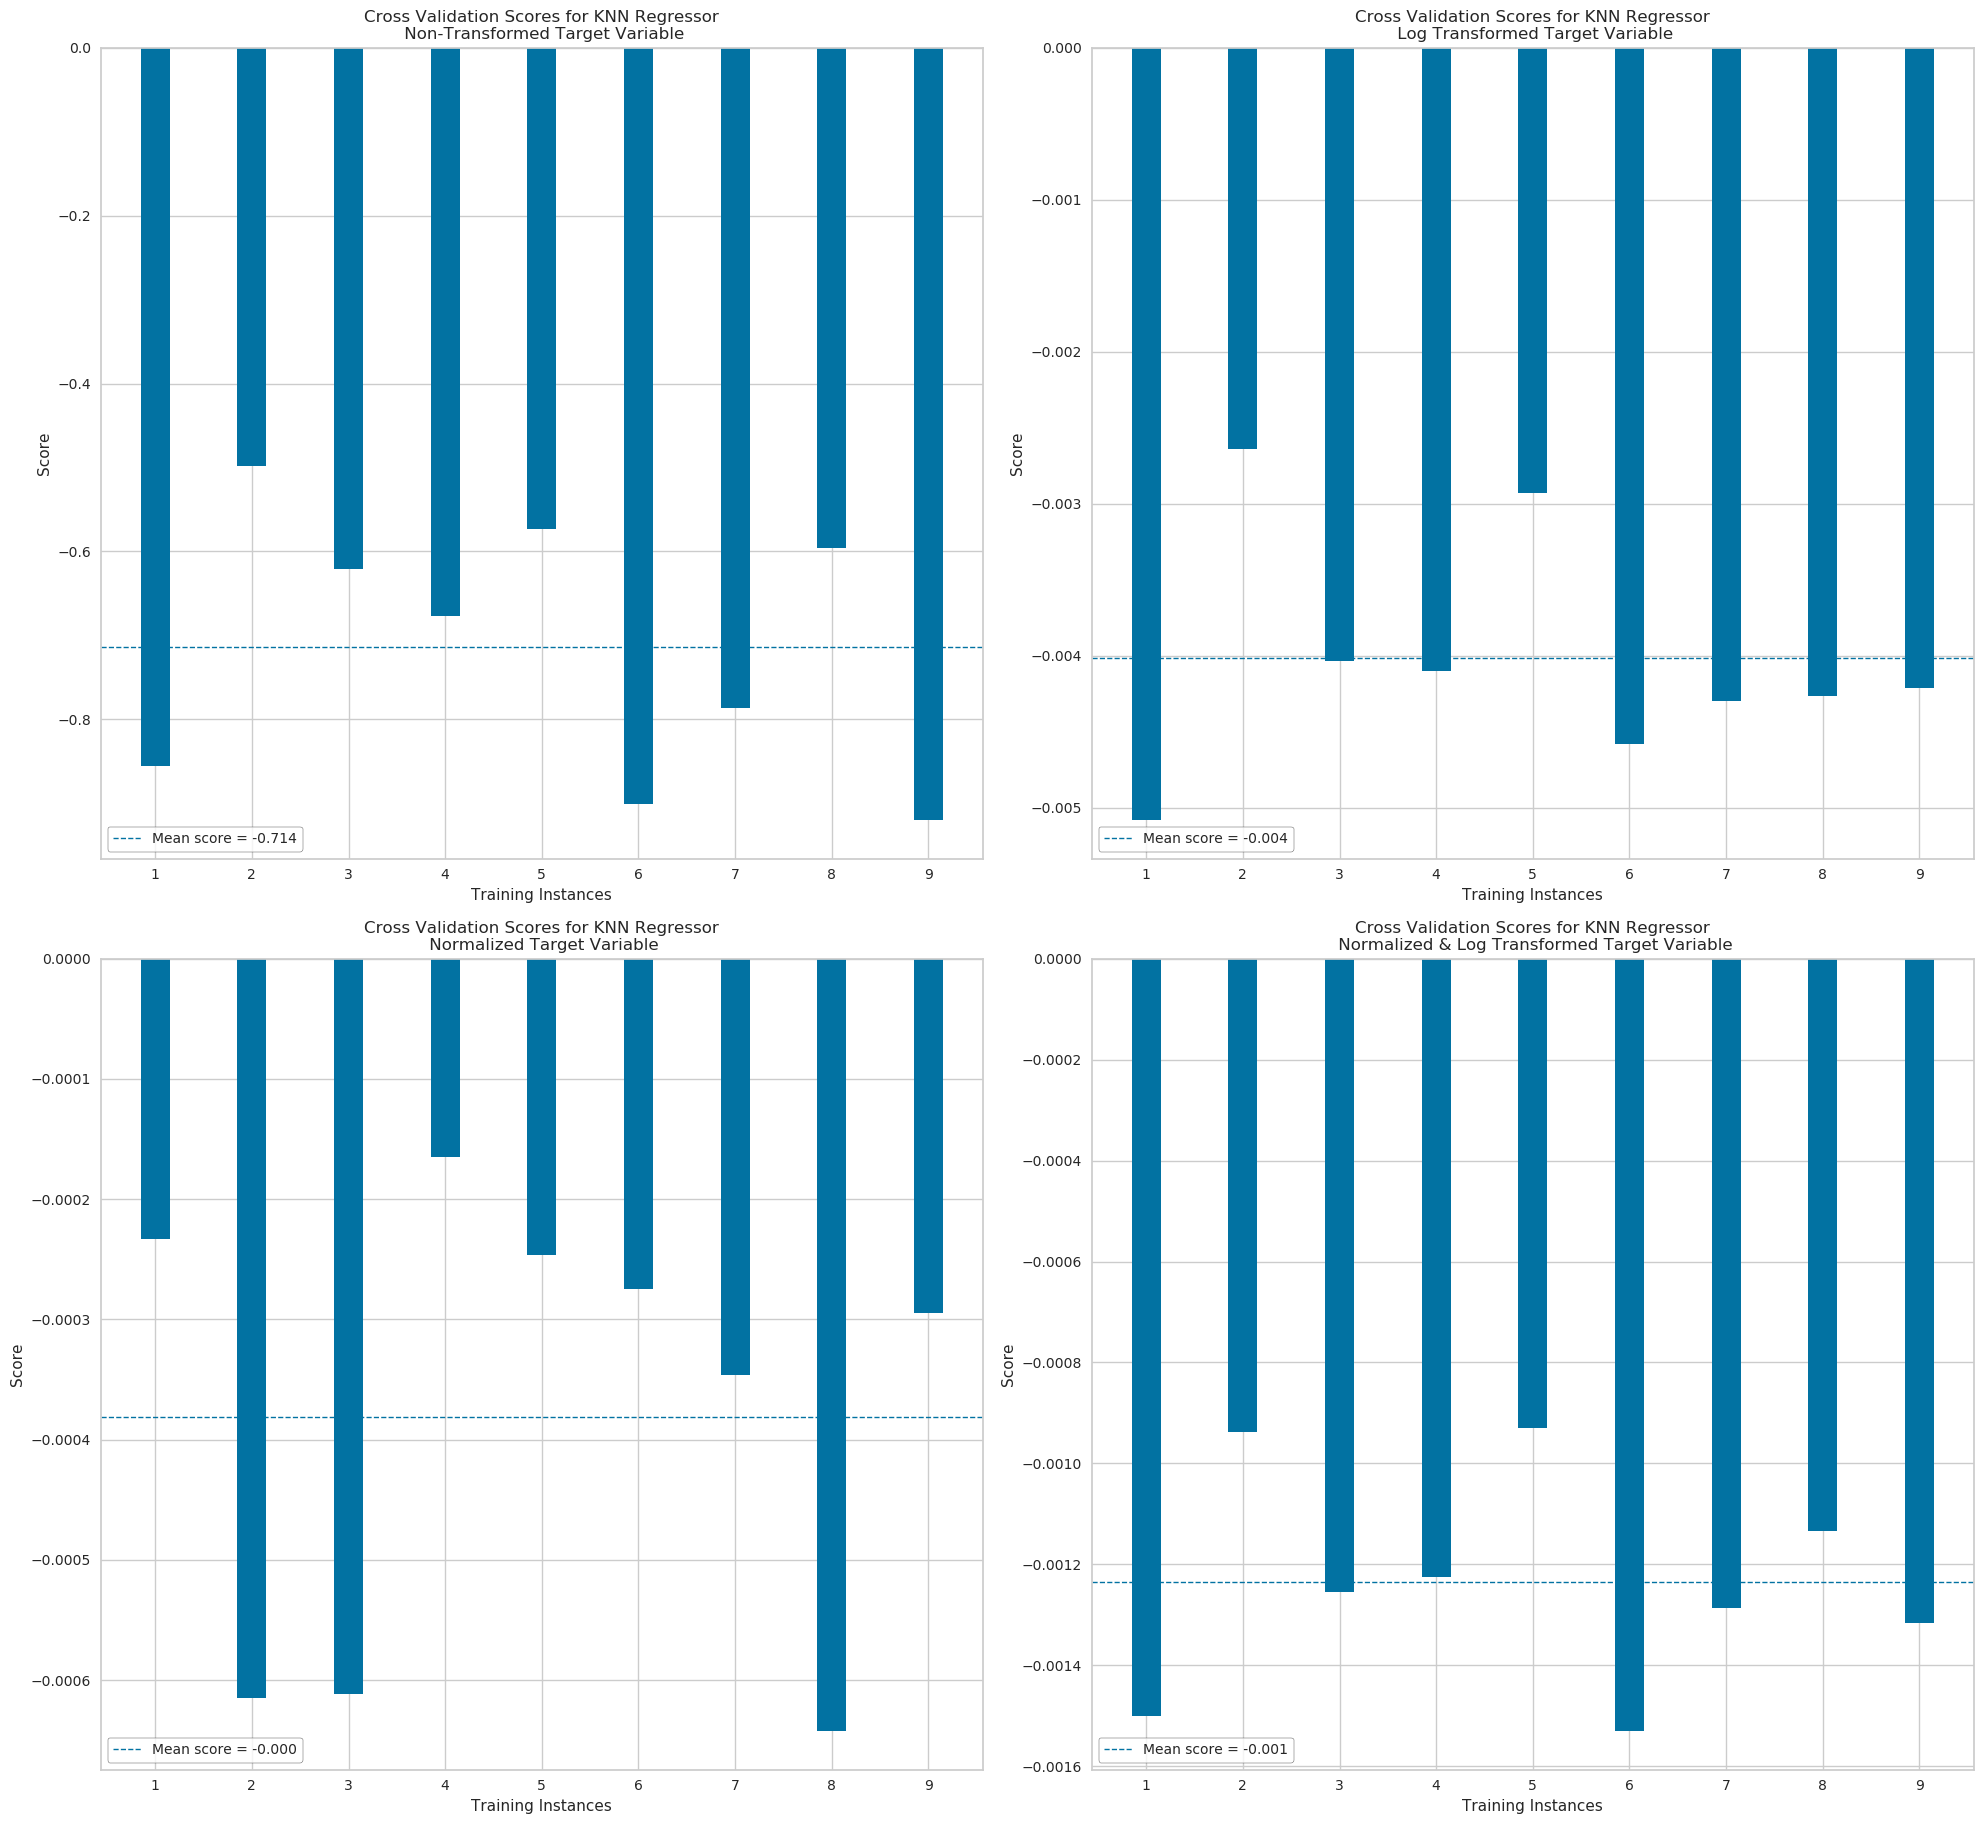

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y, groups=divisions)
model = KNeighborsRegressor(algorithm=params0['algorithm'], leaf_size=params0['leaf_size'], n_neighbors=params0['n_neighbors'], weights=params0['weights'], n_jobs=-1)
visualizer0 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[0])
visualizer0.fit(X[automatic_selected_features], y)
visualizer0.finalize()
axes[0].set_title('Cross Validation Scores for KNN Regressor\n Non-Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_log, groups=divisions)
model = KNeighborsRegressor(algorithm=params1['algorithm'], leaf_size=params1['leaf_size'], n_neighbors=params1['n_neighbors'], weights=params1['weights'], n_jobs=-1)
visualizer1 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[1])
visualizer1.fit(X[automatic_selected_features], y_log)
visualizer1.finalize()
axes[1].set_title('Cross Validation Scores for KNN Regressor\n Log Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_normalized, groups=divisions)
model = KNeighborsRegressor(algorithm=params2['algorithm'], leaf_size=params2['leaf_size'], n_neighbors=params2['n_neighbors'], weights=params2['weights'], n_jobs=-1)
visualizer2 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[2])
visualizer2.fit(X[automatic_selected_features], y_normalized)
visualizer2.finalize()
axes[2].set_title('Cross Validation Scores for KNN Regressor\n Normalized Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_log_normalized, groups=divisions)
model = KNeighborsRegressor(algorithm=params3['algorithm'], leaf_size=params3['leaf_size'], n_neighbors=params3['n_neighbors'], weights=params3['weights'], n_jobs=-1)
visualizer3 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[3])
visualizer3.fit(X[automatic_selected_features], y_log_normalized)
visualizer3.finalize()
axes[3].set_title('Cross Validation Scores for KNN Regressor\n Normalized & Log Transformed Target Variable')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../images/crossvalidationscores_automaticfeatures_knn.png', dpi=300)

In [19]:
params0 = knn_regressor_gridsearch(other_features, y, 'neg_mean_squared_log_error')
params1 = knn_regressor_gridsearch(other_features, y_normalized, 'neg_mean_squared_log_error')
params2 = knn_regressor_gridsearch(other_features, y_log, 'neg_mean_squared_log_error')
params3 = knn_regressor_gridsearch(other_features, y_log_normalized, 'neg_mean_squared_log_error')

print('\n')

average_score_otherfeatures_nontransformed_knn = knn_regressor_crossvalidation(other_features, y, y_train, y_test, 'neg_mean_squared_log_error', params0)
average_score_otherfeatures_normalized_knn = knn_regressor_crossvalidation(other_features, y_normalized, y_train_normalized, y_test_normalized, 'neg_mean_squared_log_error', params1)
average_score_otherfeatures_log_knn = knn_regressor_crossvalidation(other_features, y_log, y_train_log, y_test_log, 'neg_mean_squared_log_error', params2)
average_score_otherfeatures_log_normalized_knn = knn_regressor_crossvalidation(other_features, y_log_normalized, y_train_log_normalized, y_test_log_normalized, 'neg_mean_squared_log_error', params3)    

Best parameters of the k-nearest neighbors regressor are: {'algorithm': 'auto', 'leaf_size': 20, 'n_neighbors': 4, 'weights': 'distance'}
Best score with the best parameters is: -1.76
Average score is: -1.83 

Best parameters of the k-nearest neighbors regressor are: {'algorithm': 'auto', 'leaf_size': 20, 'n_neighbors': 5, 'weights': 'distance'}
Best score with the best parameters is: -0.00
Average score is: -0.00 

Best parameters of the k-nearest neighbors regressor are: {'algorithm': 'ball_tree', 'leaf_size': 20, 'n_neighbors': 8, 'weights': 'distance'}
Best score with the best parameters is: -0.00
Average score is: -0.00 

Best parameters of the k-nearest neighbors regressor are: {'algorithm': 'ball_tree', 'leaf_size': 20, 'n_neighbors': 8, 'weights': 'distance'}
Best score with the best parameters is: -0.00
Average score is: -0.00 



CrossValPredict MSLE is 1.7115744357640759
TrainTestSplit MSLE is 1.078680706819383
Average MSLE is -1.766441998415778
Best MSLE is -1.0786807068193

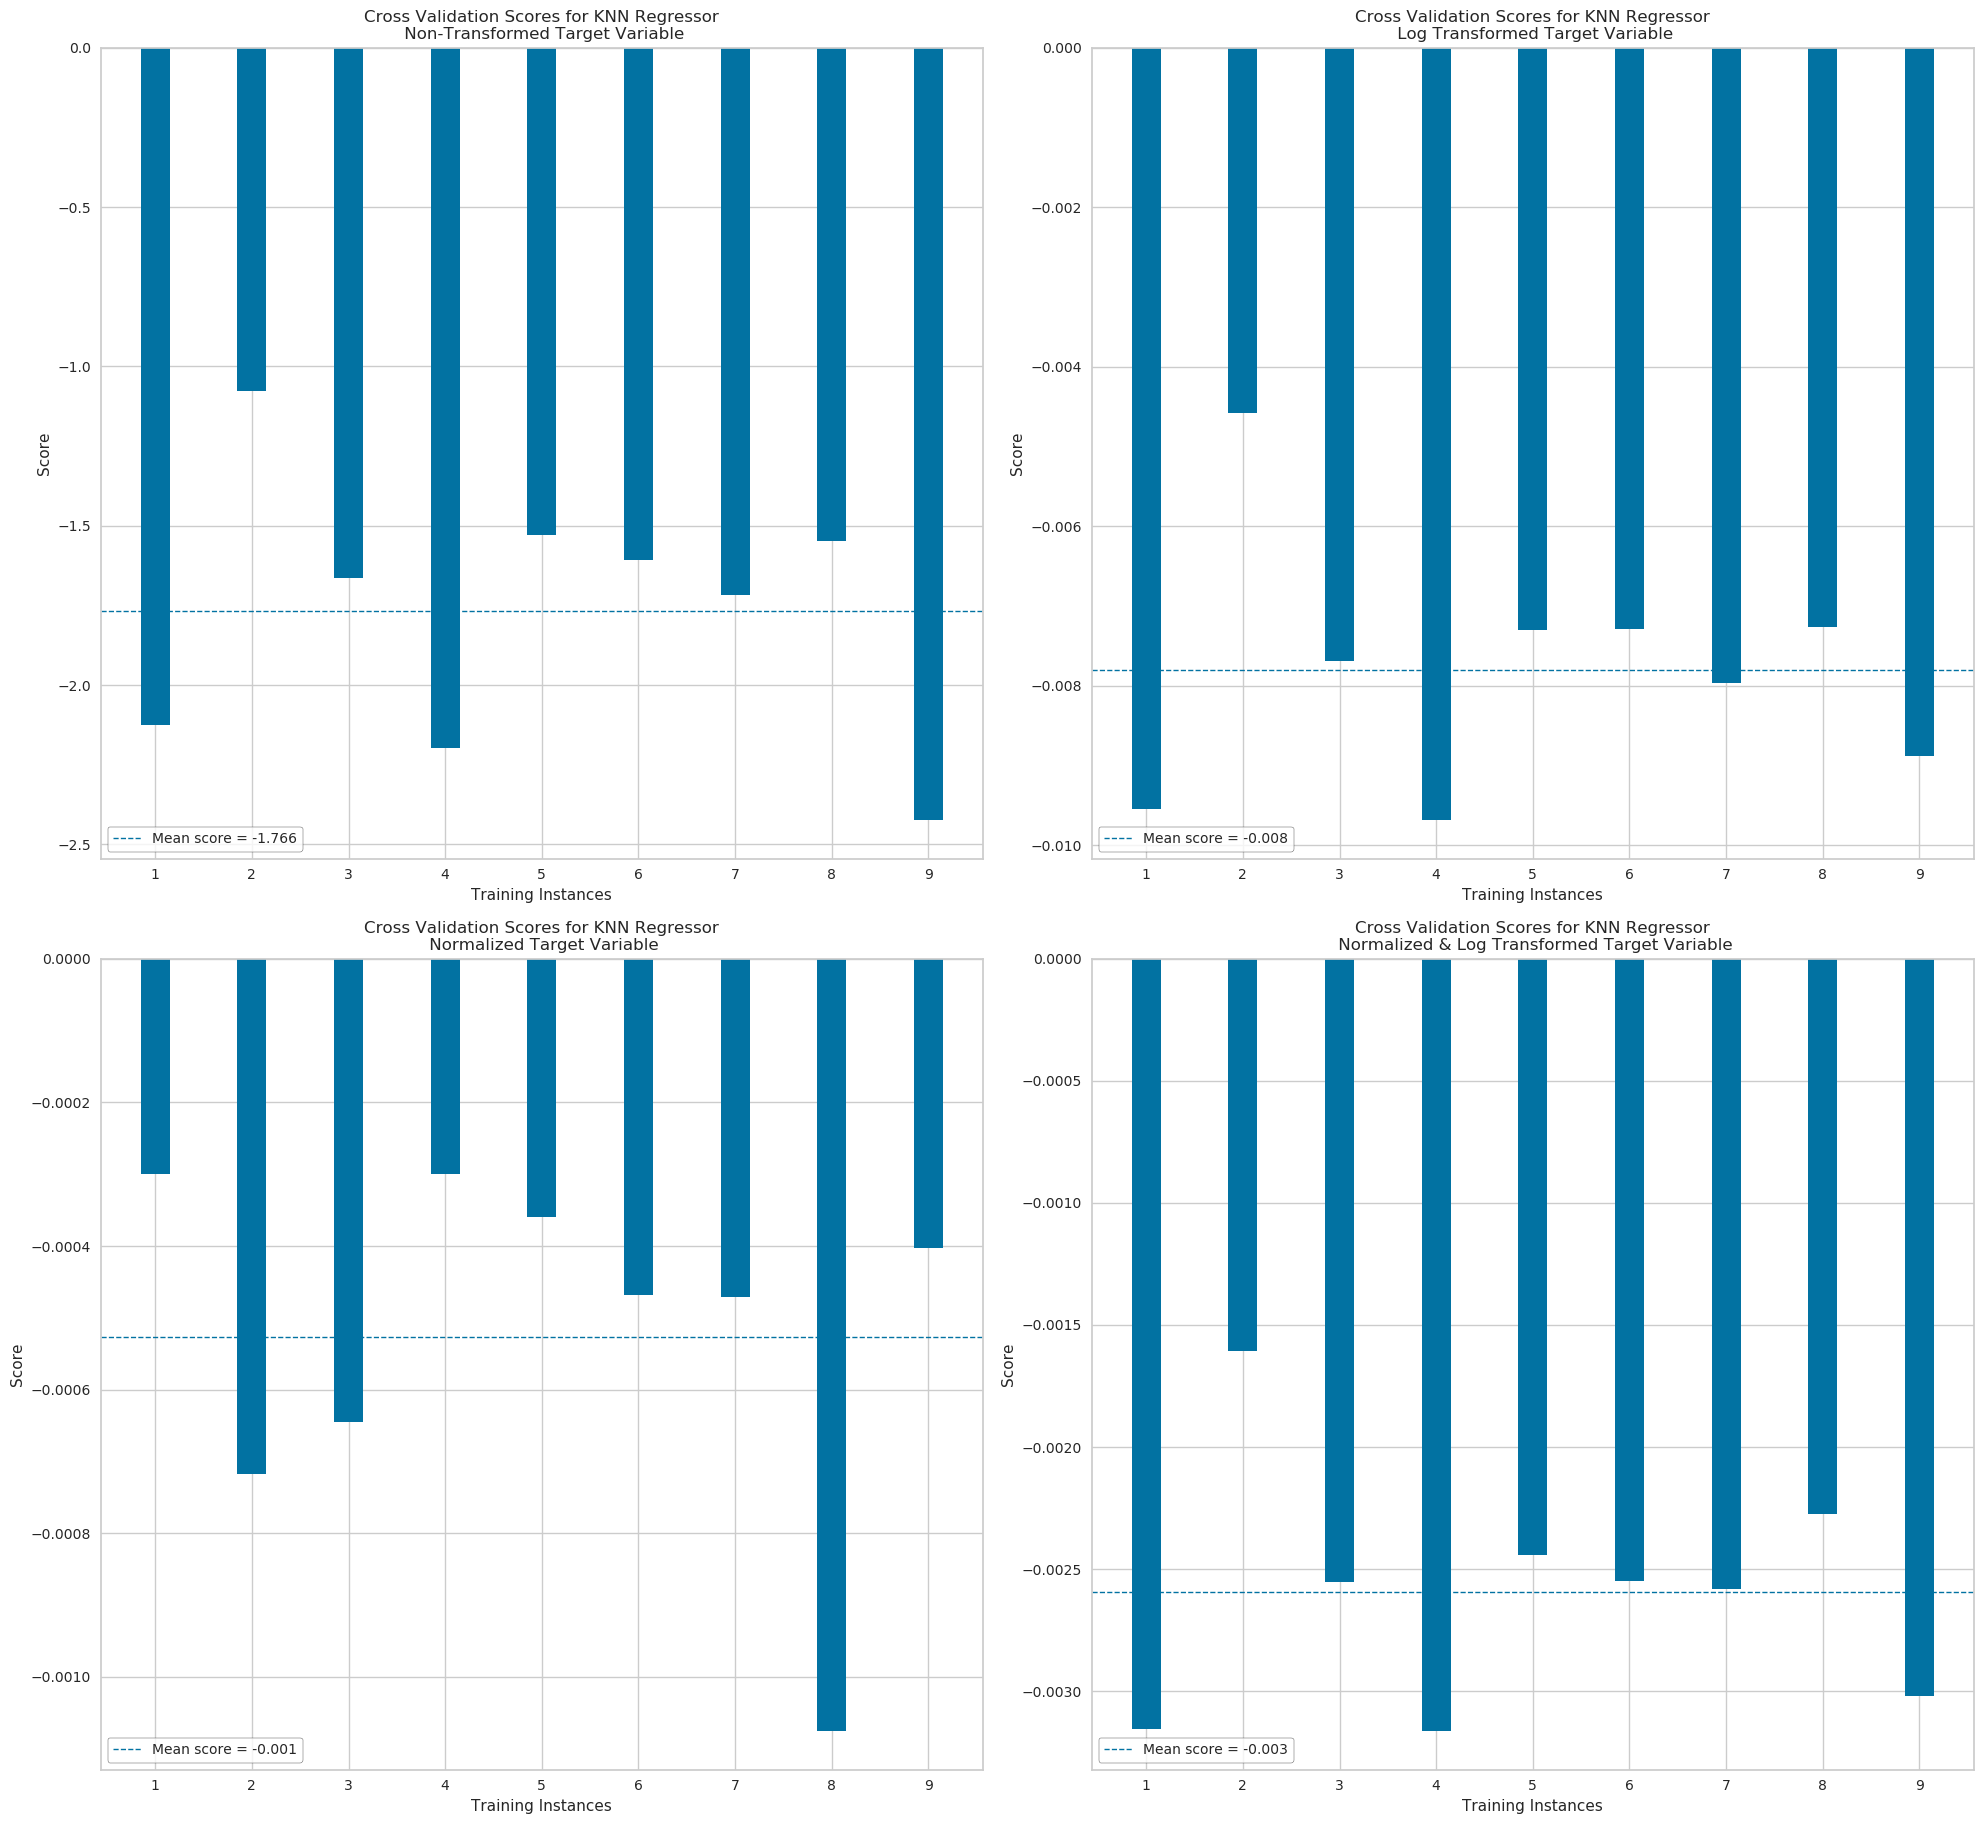

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y, groups=divisions)
model = KNeighborsRegressor(algorithm=params0['algorithm'], leaf_size=params0['leaf_size'], n_neighbors=params0['n_neighbors'], weights=params0['weights'], n_jobs=-1)
visualizer0 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[0])
visualizer0.fit(X[other_features], y)
visualizer0.finalize()
axes[0].set_title('Cross Validation Scores for KNN Regressor\n Non-Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_log, groups=divisions)
model = KNeighborsRegressor(algorithm=params1['algorithm'], leaf_size=params1['leaf_size'], n_neighbors=params1['n_neighbors'], weights=params1['weights'], n_jobs=-1)
visualizer1 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[1])
visualizer1.fit(X[other_features], y_log)
visualizer1.finalize()
axes[1].set_title('Cross Validation Scores for KNN Regressor\n Log Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_normalized, groups=divisions)
model = KNeighborsRegressor(algorithm=params2['algorithm'], leaf_size=params2['leaf_size'], n_neighbors=params2['n_neighbors'], weights=params2['weights'], n_jobs=-1)
visualizer2 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[2])
visualizer2.fit(X[other_features], y_normalized)
visualizer2.finalize()
axes[2].set_title('Cross Validation Scores for KNN Regressor\n Normalized Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_log_normalized, groups=divisions)
model = KNeighborsRegressor(algorithm=params3['algorithm'], leaf_size=params3['leaf_size'], n_neighbors=params3['n_neighbors'], weights=params3['weights'], n_jobs=-1)
visualizer3 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[3])
visualizer3.fit(X[other_features], y_log_normalized)
visualizer3.finalize()
axes[3].set_title('Cross Validation Scores for KNN Regressor\n Normalized & Log Transformed Target Variable')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../images/crossvalidationscores_otherfeatures_knn.png', dpi=300)

In [21]:
print(pd.DataFrame(list(zip(['Non Transformed Target', 'Normalized Target', 'Log Transformation', 'Normalized Log Transformation'], 
                   [average_score_automaticfeatures_nontransformed_knn * -1, average_score_automaticfeatures_normalized_knn * -1, 
                    average_score_automaticfeatures_log_knn * -1, average_score_automaticfeatures_log_normalized_knn * -1],
                   [average_score_otherfeatures_nontransformed_knn * -1, average_score_otherfeatures_normalized_knn * -1, 
                    average_score_otherfeatures_log_knn * -1, average_score_otherfeatures_log_normalized_knn * -1])),
                   columns=['Transformation of Target Variable', 'Cross Validated Average MSLE for Automatically Selected Features',
                            'Cross Validated Average MSLE for Other Selected Features']).to_latex(index=False))

\begin{tabular}{lrr}
\toprule
Transformation of Target Variable &  Cross Validated Average MSLE for Automatically Selected Features &  Cross Validated Average MSLE for Other Selected Features \\
\midrule
           Non Transformed Target &                                           0.714011 &                                           1.766442 \\
                Normalized Target &                                           0.000370 &                                           0.000520 \\
               Log Transformation &                                           0.003712 &                                           0.007576 \\
    Normalized Log Transformation &                                           0.001235 &                                           0.002593 \\
\bottomrule
\end{tabular}



### **AdaBoost Regression**

In [22]:
def adaboost_regressor_gridsearch(features, target, scoring_metric):
    
    logo = LeaveOneGroupOut()
    adaboost_regressor = AdaBoostRegressor(random_state=42)

    parameters = {
        'n_estimators':list(range(50,2000,500)),
        'learning_rate':[1.0, 1.5, 2.0, 2.5, 3.0],
        'loss':['linear', 'square', 'exponential'],
    }


    adaboost_regressor_gridsearch = GridSearchCV(adaboost_regressor, parameters, scoring='neg_mean_squared_log_error', cv=logo, n_jobs=-1)
    adaboost_regressor_gridsearch.fit(X[features], y=target, groups=divisions)
    print("Best parameters of the AdaBoost regressor are: %s" % adaboost_regressor_gridsearch.best_params_)
    print("Best mean squared log error score with the best parameters is: %.5s" % adaboost_regressor_gridsearch.best_score_)
    print("Average mean squared log error score is: %.5s \n" % adaboost_regressor_gridsearch.cv_results_["mean_test_score"].mean())
    
    return adaboost_regressor_gridsearch.best_params_


def adaboost_regressor_crossvalidation(features, target, target_train, target_test, scoring_metric, params):
    
    logo = LeaveOneGroupOut()
    logo_cv = logo.split(X[features], target, groups=divisions)
    adaboost_regressor = AdaBoostRegressor(learning_rate=params['learning_rate'], loss=params['loss'], n_estimators=params['n_estimators'], random_state=42)

    y_predict1 = cross_val_predict(adaboost_regressor, X[features], target, groups=divisions, cv=logo_cv, n_jobs=-1)
    scores = cross_validate(adaboost_regressor, X[features], target, groups=divisions, cv=logo, scoring=scoring_metric, return_estimator=True)
    
    adaboost_regressor.fit(X_train[features], target_train)
    y_predict2 = adaboost_regressor.predict(X_test[features])
    
    if scoring_metric is 'r2':
        print('CrossValPredict R2 is %s' % r2_score(target, y_predict1))
        print('TrainTestSplit R2 is %s' % r2_score(target_test, y_predict2))
        print('Average R2 is %s' % scores['test_score'].mean())
        print('Best R2 is %s\n' % scores['test_score'].max())
    elif scoring_metric is 'neg_mean_squared_log_error':
        print('CrossValPredict MSLE is %s' % mean_squared_log_error(target, y_predict1))
        print('TrainTestSplit MSLE is %s' % mean_squared_log_error(target_test, y_predict2))
        print('Average MSLE is %s' % scores['test_score'].mean())
        print('Best MSLE is %s\n' % scores['test_score'].max())
        
    return scores['test_score'].mean()

In [23]:
params0 = adaboost_regressor_gridsearch(automatic_selected_features, y, 'neg_mean_squared_log_error')
params1 = adaboost_regressor_gridsearch(automatic_selected_features, y_normalized, 'neg_mean_squared_log_error')
params2 = adaboost_regressor_gridsearch(automatic_selected_features, y_log, 'neg_mean_squared_log_error')
params3 = adaboost_regressor_gridsearch(automatic_selected_features, y_log_normalized, 'neg_mean_squared_log_error')

print('\n')

average_score_automaticfeatures_nontransformed_ab = adaboost_regressor_crossvalidation(automatic_selected_features, y, y_train, y_test, 'neg_mean_squared_log_error', params0)
average_score_automaticfeatures_normalized_ab = adaboost_regressor_crossvalidation(automatic_selected_features, y_normalized, y_train_normalized, y_test_normalized, 'neg_mean_squared_log_error', params1)
average_score_automaticfeatures_log_ab = adaboost_regressor_crossvalidation(automatic_selected_features, y_log, y_train_log, y_test_log, 'neg_mean_squared_log_error', params2)
average_score_automaticfeatures_log_normalized_ab = adaboost_regressor_crossvalidation(automatic_selected_features, y_log_normalized, y_train_log_normalized, y_test_log_normalized, 'neg_mean_squared_log_error', params3)    

Best parameters of the AdaBoost regressor are: {'learning_rate': 3.0, 'loss': 'square', 'n_estimators': 1550}
Best mean squared log error score with the best parameters is: -6.37
Average mean squared log error score is: -12.5 

Best parameters of the AdaBoost regressor are: {'learning_rate': 2.5, 'loss': 'square', 'n_estimators': 1050}
Best mean squared log error score with the best parameters is: -0.00
Average mean squared log error score is: -0.00 

Best parameters of the AdaBoost regressor are: {'learning_rate': 1.0, 'loss': 'linear', 'n_estimators': 50}
Best mean squared log error score with the best parameters is: -0.00
Average mean squared log error score is: -0.09 

Best parameters of the AdaBoost regressor are: {'learning_rate': 1.0, 'loss': 'linear', 'n_estimators': 50}
Best mean squared log error score with the best parameters is: -0.00
Average mean squared log error score is: -0.01 



CrossValPredict MSLE is 6.803360375481256
TrainTestSplit MSLE is 3.9130491618801333
Averag

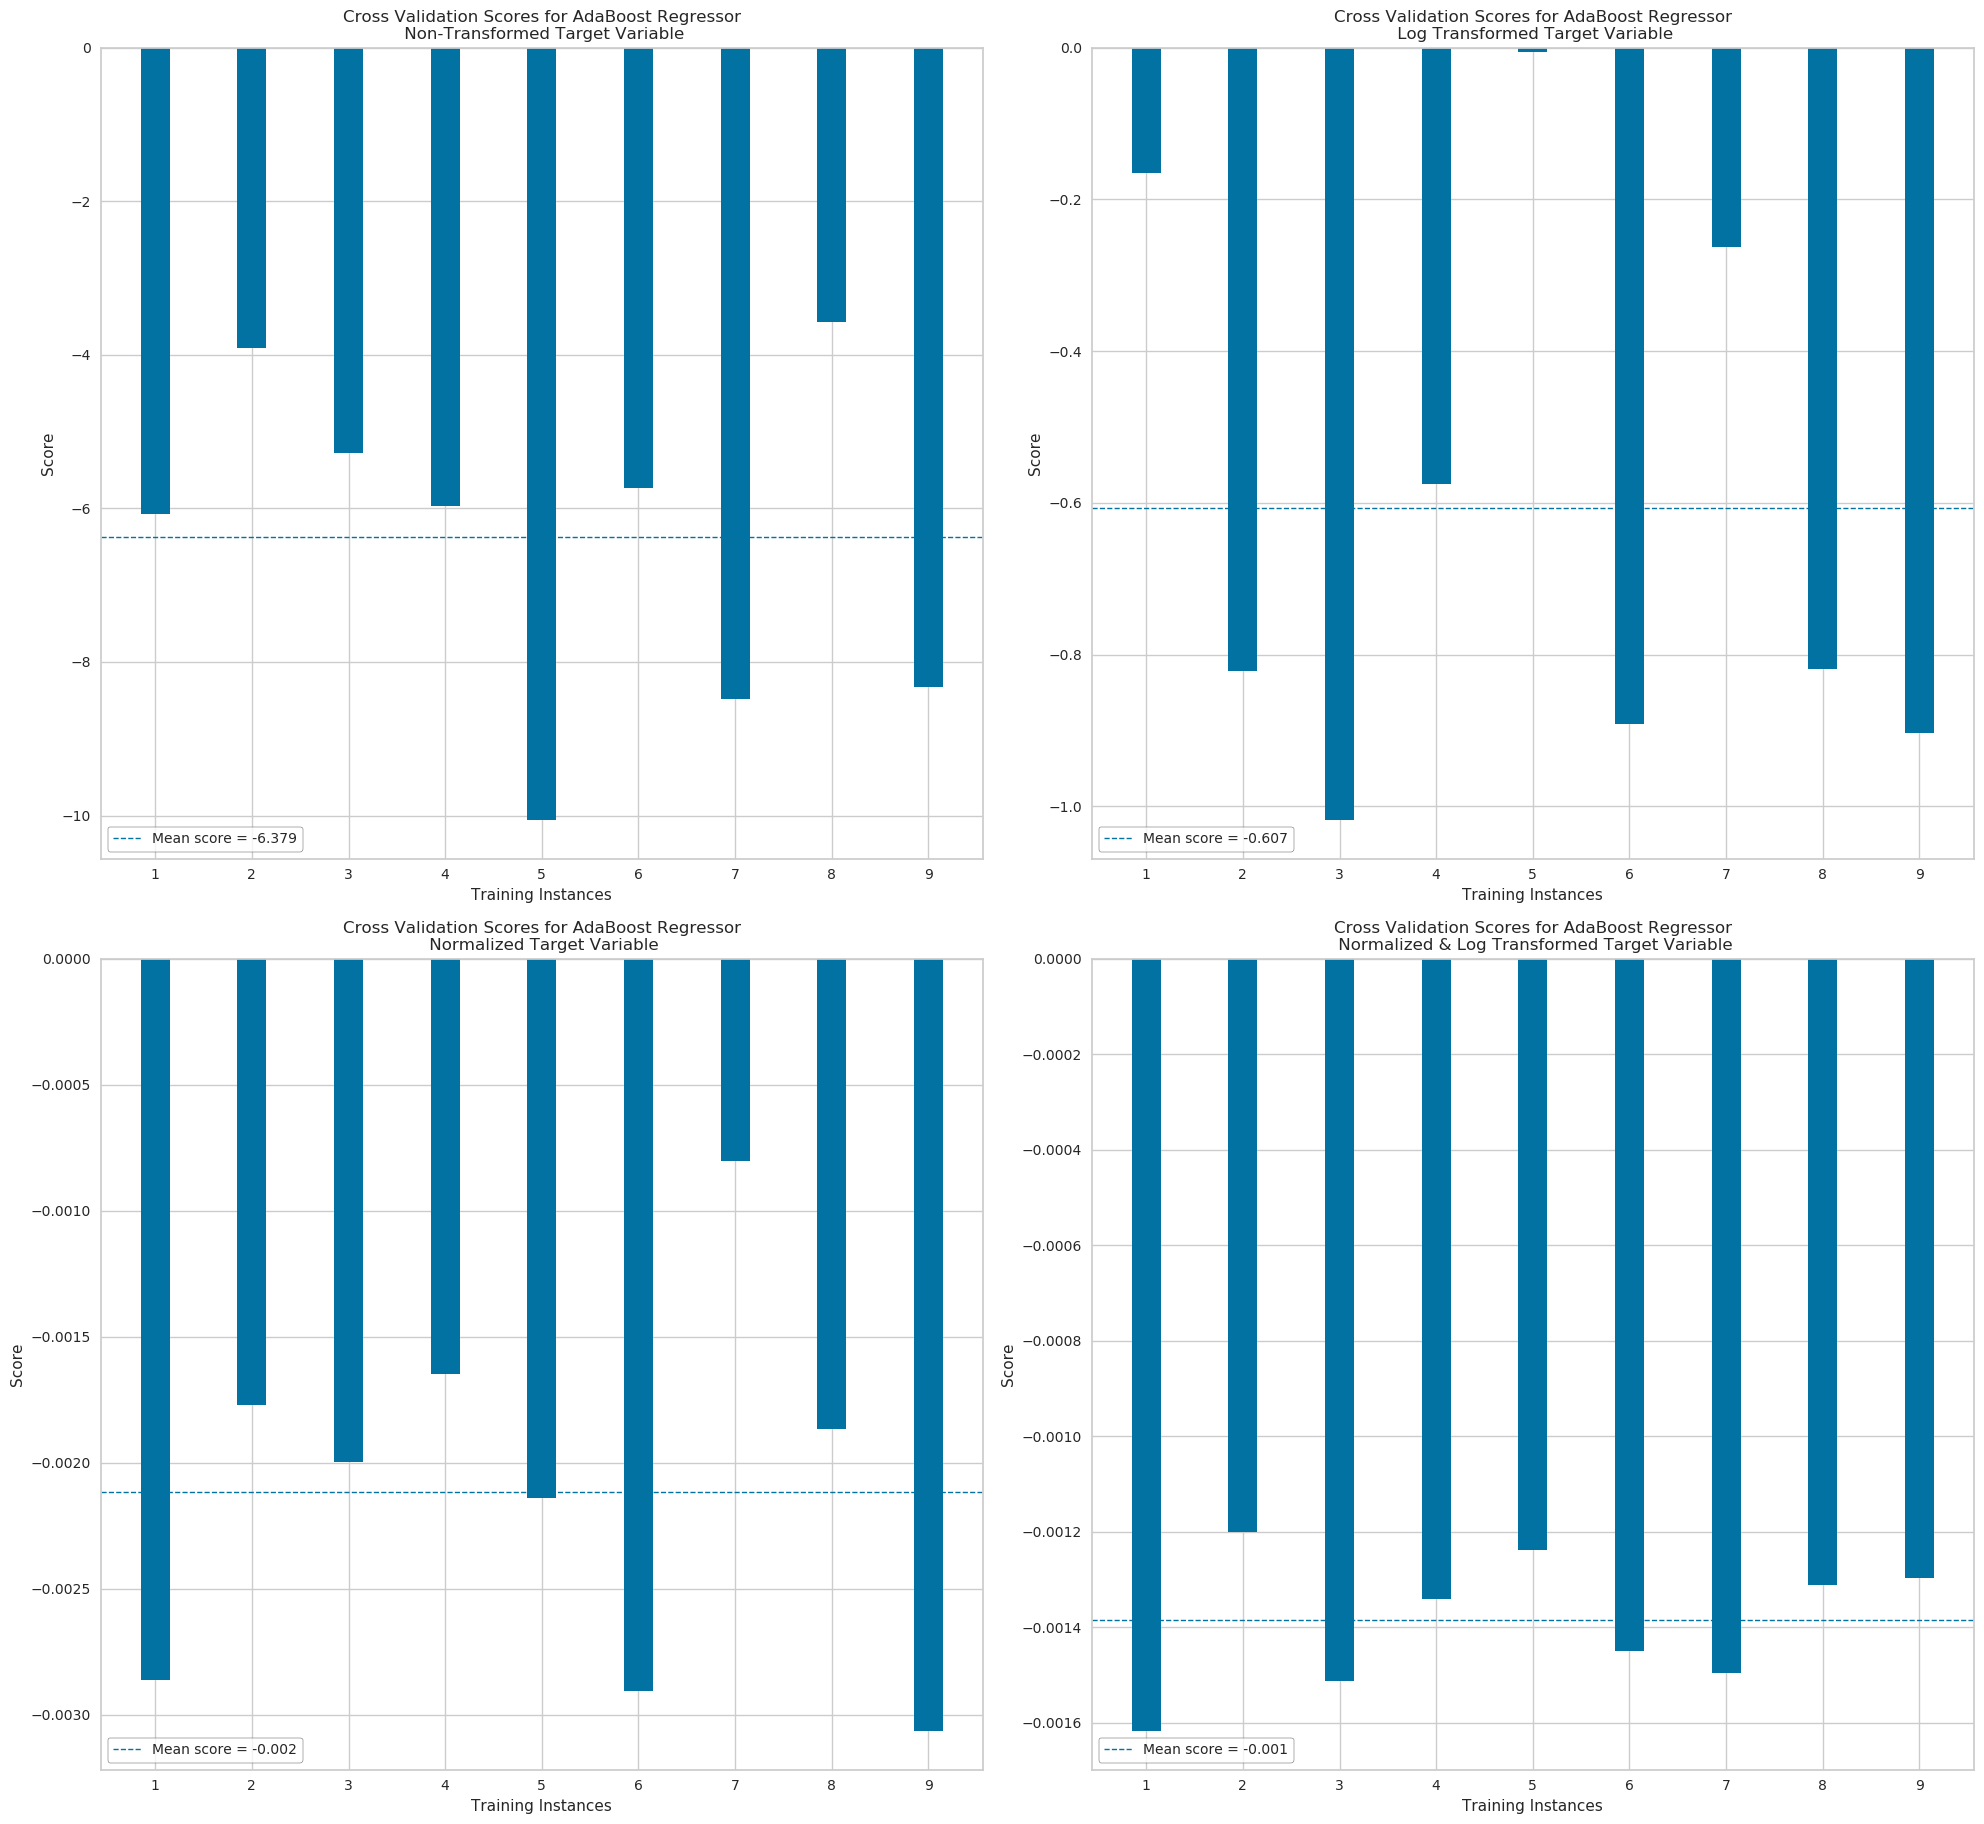

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y, groups=divisions)
model = AdaBoostRegressor(learning_rate=params0['learning_rate'], loss=params0['loss'], n_estimators=params0['n_estimators'], random_state=42)
visualizer0 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[0])
visualizer0.fit(X[automatic_selected_features], y)
visualizer0.finalize()
axes[0].set_title('Cross Validation Scores for AdaBoost Regressor\n Non-Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_log, groups=divisions)
model = AdaBoostRegressor(learning_rate=params1['learning_rate'], loss=params1['loss'], n_estimators=params1['n_estimators'], random_state=42)
visualizer1 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[1])
visualizer1.fit(X[automatic_selected_features], y_log)
visualizer1.finalize()
axes[1].set_title('Cross Validation Scores for AdaBoost Regressor\n Log Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_normalized, groups=divisions)
model = AdaBoostRegressor(learning_rate=params2['learning_rate'], loss=params2['loss'], n_estimators=params2['n_estimators'], random_state=42)
visualizer2 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[2])
visualizer2.fit(X[automatic_selected_features], y_normalized)
visualizer2.finalize()
axes[2].set_title('Cross Validation Scores for AdaBoost Regressor\n Normalized Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_log_normalized, groups=divisions)
model = AdaBoostRegressor(learning_rate=params3['learning_rate'], loss=params3['loss'], n_estimators=params3['n_estimators'], random_state=42)
visualizer3 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[3])
visualizer3.fit(X[automatic_selected_features], y_log_normalized)
visualizer3.finalize()
axes[3].set_title('Cross Validation Scores for AdaBoost Regressor\n Normalized & Log Transformed Target Variable')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../images/crossvalidationscores_automaticfeatures_adaboost.png', dpi=300)

In [25]:
params0 = adaboost_regressor_gridsearch(other_features, y, 'neg_mean_squared_log_error')
params1 = adaboost_regressor_gridsearch(other_features, y_normalized, 'neg_mean_squared_log_error')
params2 = adaboost_regressor_gridsearch(other_features, y_log, 'neg_mean_squared_log_error')
params3 = adaboost_regressor_gridsearch(other_features, y_log_normalized, 'neg_mean_squared_log_error')

print('\n')

average_score_otherfeatures_nontransformed_ab = adaboost_regressor_crossvalidation(other_features, y, y_train, y_test, 'neg_mean_squared_log_error', params0)
average_score_otherfeatures_normalized_ab = adaboost_regressor_crossvalidation(other_features, y_normalized, y_train_normalized, y_test_normalized, 'neg_mean_squared_log_error', params1)
average_score_otherfeatures_log_ab = adaboost_regressor_crossvalidation(other_features, y_log, y_train_log, y_test_log, 'neg_mean_squared_log_error', params2)
average_score_otherfeatures_log_normalized_ab = adaboost_regressor_crossvalidation(other_features, y_log_normalized, y_train_log_normalized, y_test_log_normalized, 'neg_mean_squared_log_error', params3)    

Best parameters of the AdaBoost regressor are: {'learning_rate': 2.5, 'loss': 'square', 'n_estimators': 1050}
Best mean squared log error score with the best parameters is: -5.79
Average mean squared log error score is: -13.0 

Best parameters of the AdaBoost regressor are: {'learning_rate': 1.0, 'loss': 'square', 'n_estimators': 50}
Best mean squared log error score with the best parameters is: -0.00
Average mean squared log error score is: -0.00 

Best parameters of the AdaBoost regressor are: {'learning_rate': 3.0, 'loss': 'linear', 'n_estimators': 50}
Best mean squared log error score with the best parameters is: -0.00
Average mean squared log error score is: -0.05 

Best parameters of the AdaBoost regressor are: {'learning_rate': 1.0, 'loss': 'exponential', 'n_estimators': 50}
Best mean squared log error score with the best parameters is: -0.00
Average mean squared log error score is: -0.01 



CrossValPredict MSLE is 5.377892475454936
TrainTestSplit MSLE is 4.583274244938977
Aver

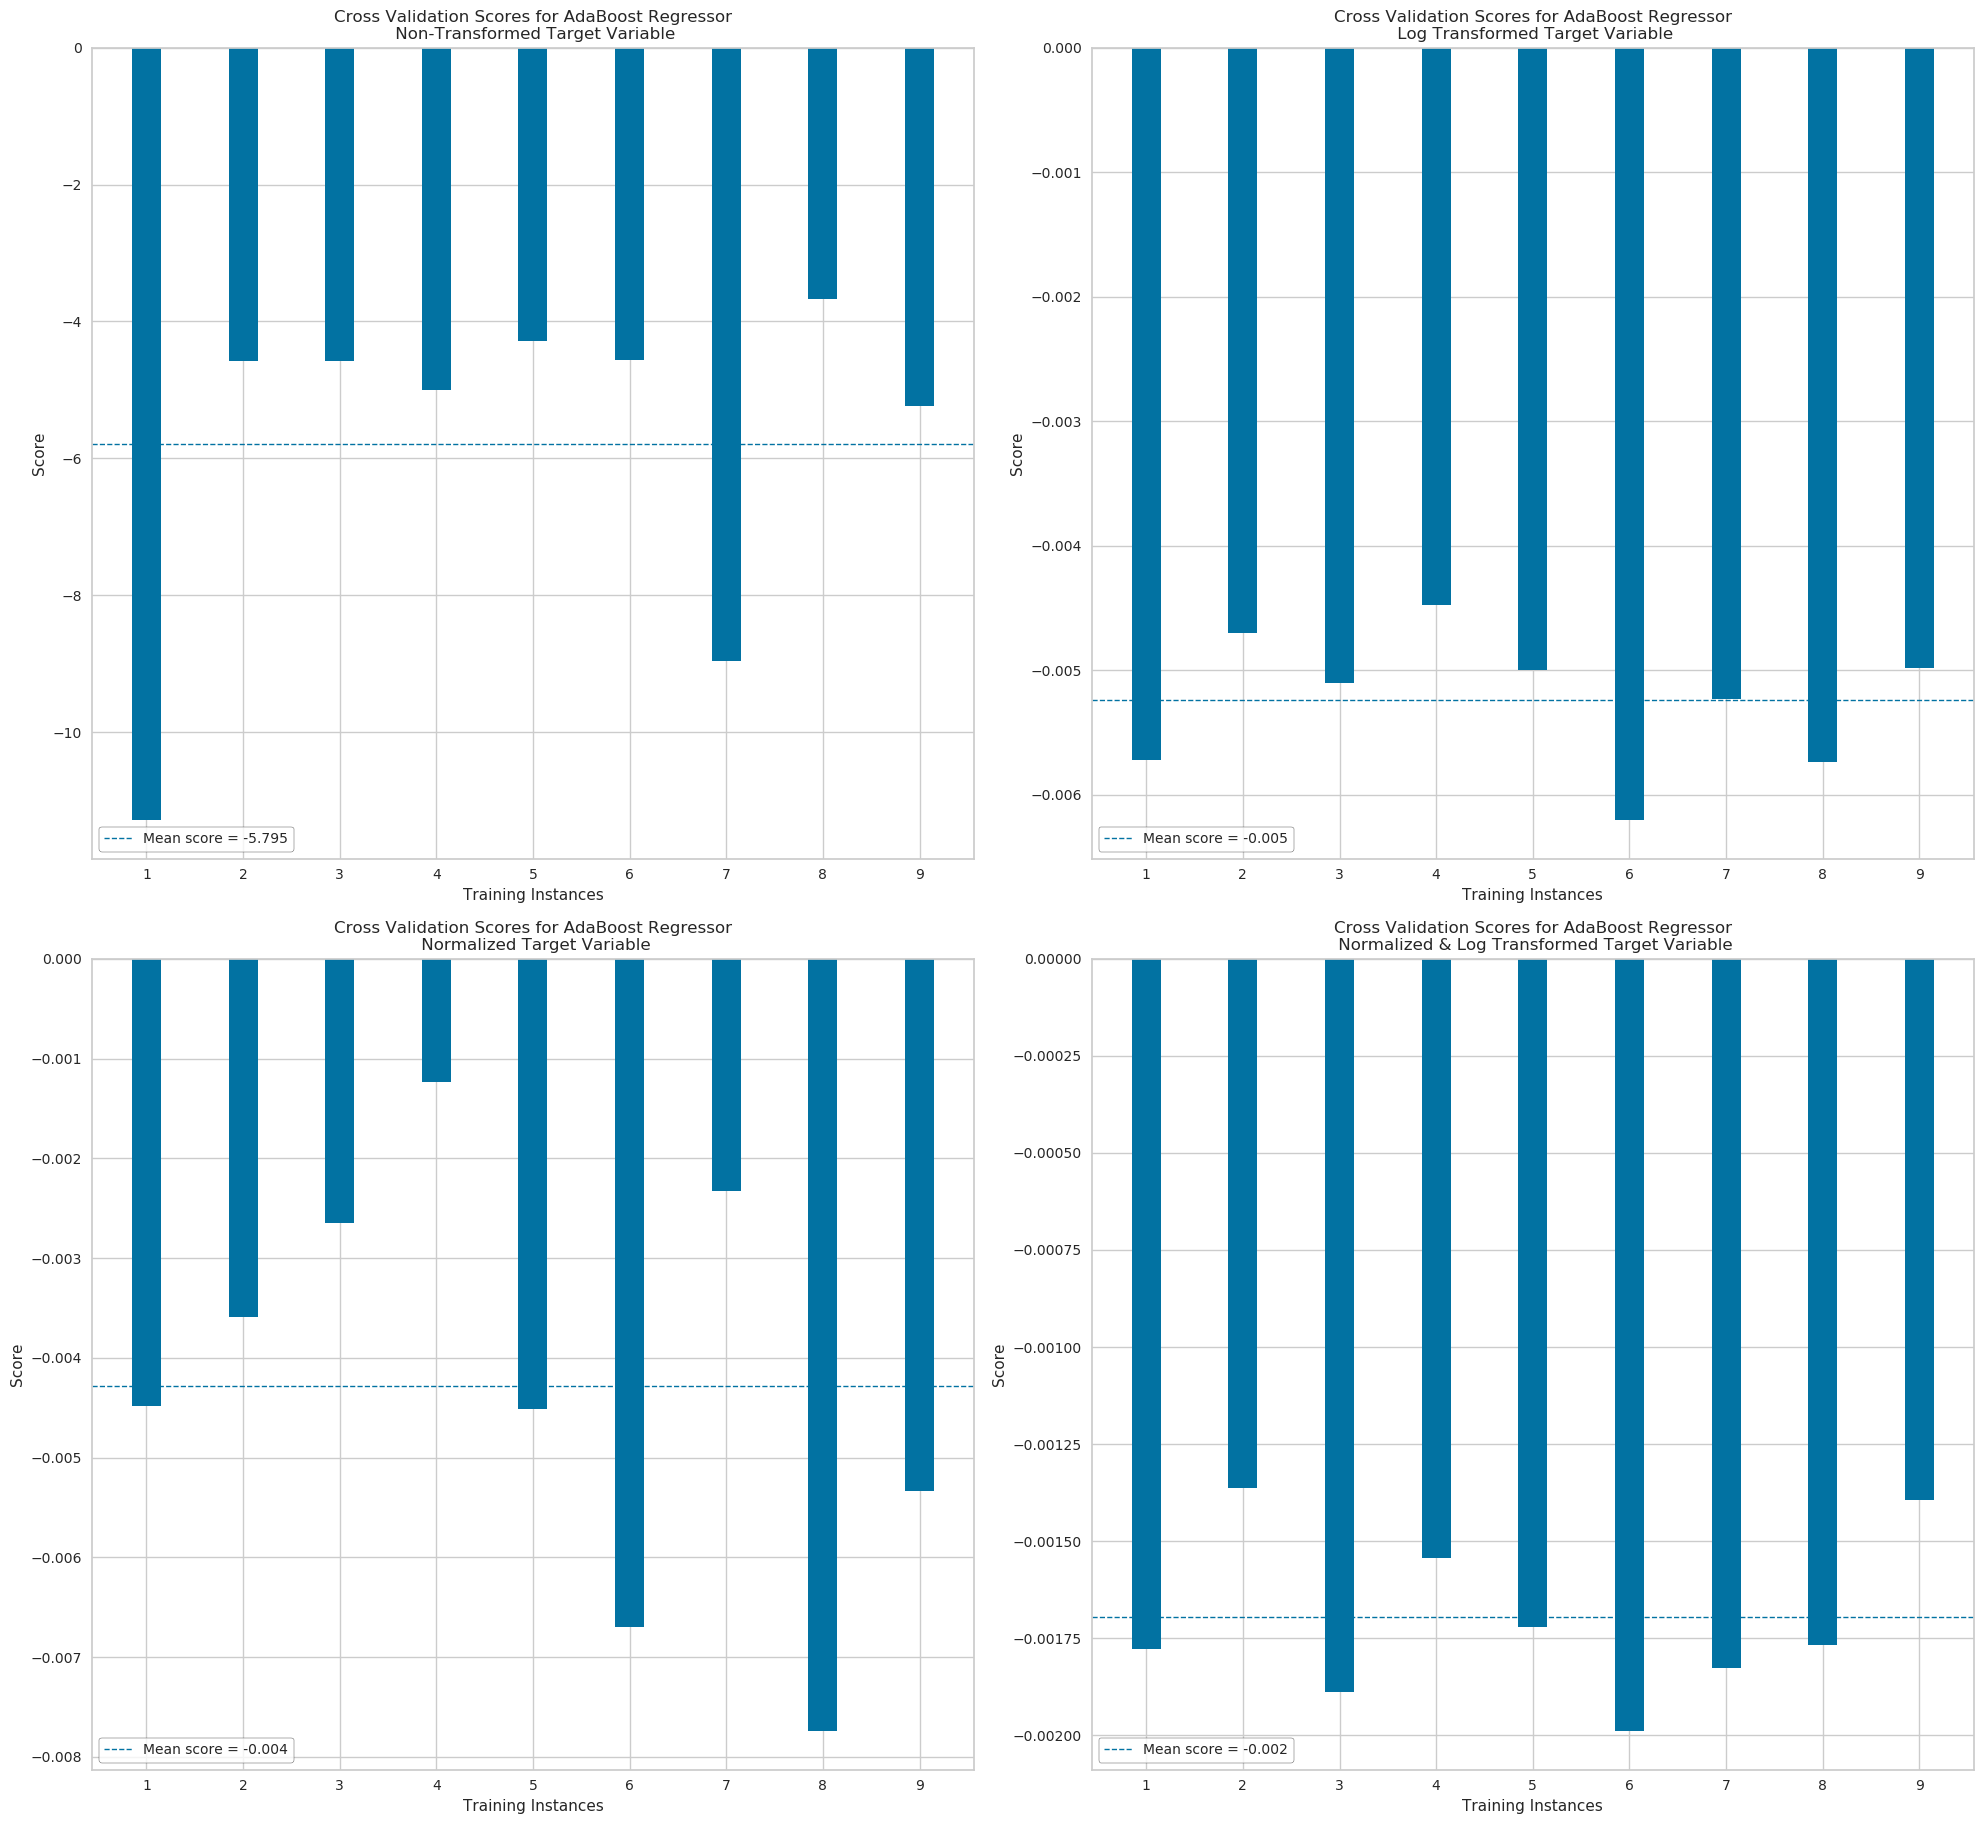

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y, groups=divisions)
model = AdaBoostRegressor(learning_rate=params0['learning_rate'], loss=params0['loss'], n_estimators=params0['n_estimators'], random_state=42)
visualizer0 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[0])
visualizer0.fit(X[other_features], y)
visualizer0.finalize()
axes[0].set_title('Cross Validation Scores for AdaBoost Regressor\n Non-Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_log, groups=divisions)
model = AdaBoostRegressor(learning_rate=params1['learning_rate'], loss=params1['loss'], n_estimators=params1['n_estimators'], random_state=42)
visualizer1 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[1])
visualizer1.fit(X[other_features], y_log)
visualizer1.finalize()
axes[1].set_title('Cross Validation Scores for AdaBoost Regressor\n Log Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_normalized, groups=divisions)
model = AdaBoostRegressor(learning_rate=params2['learning_rate'], loss=params2['loss'], n_estimators=params2['n_estimators'], random_state=42)
visualizer2 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[2])
visualizer2.fit(X[other_features], y_normalized)
visualizer2.finalize()
axes[2].set_title('Cross Validation Scores for AdaBoost Regressor\n Normalized Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_log_normalized, groups=divisions)
model = AdaBoostRegressor(learning_rate=params3['learning_rate'], loss=params3['loss'], n_estimators=params3['n_estimators'], random_state=42)
visualizer3 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[3])
visualizer3.fit(X[other_features], y_log_normalized)
visualizer3.finalize()
axes[3].set_title('Cross Validation Scores for AdaBoost Regressor\n Normalized & Log Transformed Target Variable')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../images/crossvalidationscores_otherfeatures_adaboost.png', dpi=300)

In [27]:
print(pd.DataFrame(list(zip(['Non Transformed Target', 'Normalized Target', 'Log Transformation', 'Normalized Log Transformation'], 
                   [average_score_automaticfeatures_nontransformed_ab * -1, average_score_automaticfeatures_normalized_ab * -1, 
                    average_score_automaticfeatures_log_ab * -1, average_score_automaticfeatures_log_normalized_ab * -1],
                   [average_score_otherfeatures_nontransformed_ab * -1, average_score_otherfeatures_normalized_ab * -1,
                    average_score_otherfeatures_log_ab * -1, average_score_otherfeatures_log_normalized_ab * -1])),
                   columns=['Transformation of Target Variable', 'Cross Validated Average MSLE for Automatically Selected Features',
                            'Cross Validated Average MSLE for Other Selected Features']).to_latex(index=False))

\begin{tabular}{lrr}
\toprule
Transformation of Target Variable &  Cross Validated Average MSLE for Automatically Selected Features &  Cross Validated Average MSLE for Other Selected Features \\
\midrule
           Non Transformed Target &                                           6.378734 &                                           5.795472 \\
                Normalized Target &                                           0.001472 &                                           0.001466 \\
               Log Transformation &                                           0.004131 &                                           0.004909 \\
    Normalized Log Transformation &                                           0.001385 &                                           0.001696 \\
\bottomrule
\end{tabular}



### **Gradient Boosting Regressor**

In [28]:
def gb_regressor_hyperparametertuning(features, target, scoring_metric):
    
    logo = LeaveOneGroupOut()
    gradient_boosting_regressor = GradientBoostingRegressor(random_state=42)
    space = [Integer(60,100, name="n_estimators"),
             Integer(5, 8, name='max_depth'),
             Real(0.01, 1, "log-uniform", name='learning_rate'),
             Integer(2, len(features), name='max_features'),
             Integer(100, 150, name='min_samples_split')] 

    @use_named_args(space)
    def objective(**params):
        gradient_boosting_regressor.set_params(**params)

        return -np.mean(cross_val_score(gradient_boosting_regressor, X[features], target, groups=divisions, cv=logo, n_jobs=-1,
                                        scoring=scoring_metric))

    gb_gp = gp_minimize(objective, space, n_calls=50, random_state=42)

    print("Best score is %.4f" % gb_gp.fun)

    print("""Best parameters for Gradient Boosting Regressor:
            - n_estimators=%d
            - max_depth=%d
            - learning_rate=%.6f
            - max_features=%d
            - min_samples_split=%d""" %(gb_gp.x[0], gb_gp.x[1],
                                        gb_gp.x[2], gb_gp.x[3],
                                        gb_gp.x[4]))
    
    best_params = {'n_estimators':gb_gp.x[0],
                   'max_depth':gb_gp.x[1],
                   'learning_rate':gb_gp.x[2],
                   'max_features':gb_gp.x[3],
                   'min_samples_split':gb_gp.x[4]}
    
    print("\n")
    
    return best_params



def gb_regressor_crossvalidation(features, target, target_train, target_test, scoring_metric, params):
    
    logo = LeaveOneGroupOut()
    logo_cv = logo.split(X[features], target, groups=divisions)
    gradient_boosting_regressor = GradientBoostingRegressor(n_estimators=params['n_estimators'], max_depth=params['max_depth'],
                                                            learning_rate=params['learning_rate'], max_features=params['max_features'],
                                                            min_samples_leaf=params['min_samples_split'], random_state=42)
    
    y_predict1 = cross_val_predict(gradient_boosting_regressor, X[features], target, groups=divisions, cv=logo_cv, n_jobs=-1)
    scores = cross_validate(gradient_boosting_regressor, X[features], target, groups=divisions, cv=logo, scoring=scoring_metric, return_estimator=True)
    
    gradient_boosting_regressor.fit(X_train[features], target_train)
    y_predict2 = gradient_boosting_regressor.predict(X_test[features])
    
    if scoring_metric is 'r2':
        print('CrossValPredict R2 is %s' % r2_score(target, y_predict1))
        print('TrainTestSplit R2 is %s' % r2_score(target_test, y_predict2))
        print('Average R2 is %s' % scores['test_score'].mean())
        print('Best R2 is %s\n' % scores['test_score'].max())
    elif scoring_metric is 'neg_mean_squared_log_error':
        print('CrossValPredict MSLE is %s' % mean_squared_log_error(target, y_predict1))
        print('TrainTestSplit MSLE is %s' % mean_squared_log_error(target_test, y_predict2))
        print('Average MSLE is %s' % scores['test_score'].mean())
        print('Best MSLE is %s\n' % scores['test_score'].max())
    
    return scores['test_score'].mean()

In [29]:
params0 = gb_regressor_hyperparametertuning(automatic_selected_features, y, 'r2')
params1 = gb_regressor_hyperparametertuning(automatic_selected_features, y_normalized, 'r2')
params2 = gb_regressor_hyperparametertuning(automatic_selected_features, y_log, 'neg_mean_squared_log_error')
params3 = gb_regressor_hyperparametertuning(automatic_selected_features, y_log_normalized, 'neg_mean_squared_log_error')

print('\n')
        
average_score_automaticfeatures_nontransformed_gb = gb_regressor_crossvalidation(automatic_selected_features, y, y_train, y_test, 'r2', params0)
average_score_automaticfeatures_normalized_gb = gb_regressor_crossvalidation(automatic_selected_features, y_normalized, y_train_normalized, y_test_normalized, 'r2', params1)
average_score_automaticfeatures_log_gb = gb_regressor_crossvalidation(automatic_selected_features, y_log, y_train_log, y_test_log, 'neg_mean_squared_log_error', params2)
average_score_automaticfeatures_log_normalized_gb = gb_regressor_crossvalidation(automatic_selected_features, y_log_normalized, y_train_log_normalized, y_test_log_normalized, 'neg_mean_squared_log_error', params3)    

Best score is -0.7532
Best parameters for Gradient Boosting Regressor:
            - n_estimators=100
            - max_depth=8
            - learning_rate=0.046453
            - max_features=2
            - min_samples_split=100


Best score is -0.7530
Best parameters for Gradient Boosting Regressor:
            - n_estimators=100
            - max_depth=5
            - learning_rate=0.083869
            - max_features=2
            - min_samples_split=100


Best score is 0.0030
Best parameters for Gradient Boosting Regressor:
            - n_estimators=85
            - max_depth=7
            - learning_rate=0.074302
            - max_features=4
            - min_samples_split=113


Best score is 0.0010
Best parameters for Gradient Boosting Regressor:
            - n_estimators=85
            - max_depth=7
            - learning_rate=0.074302
            - max_features=4
            - min_samples_split=113




CrossValPredict R2 is 0.6857291107304173
TrainTestSplit R2 is 0.6678485748

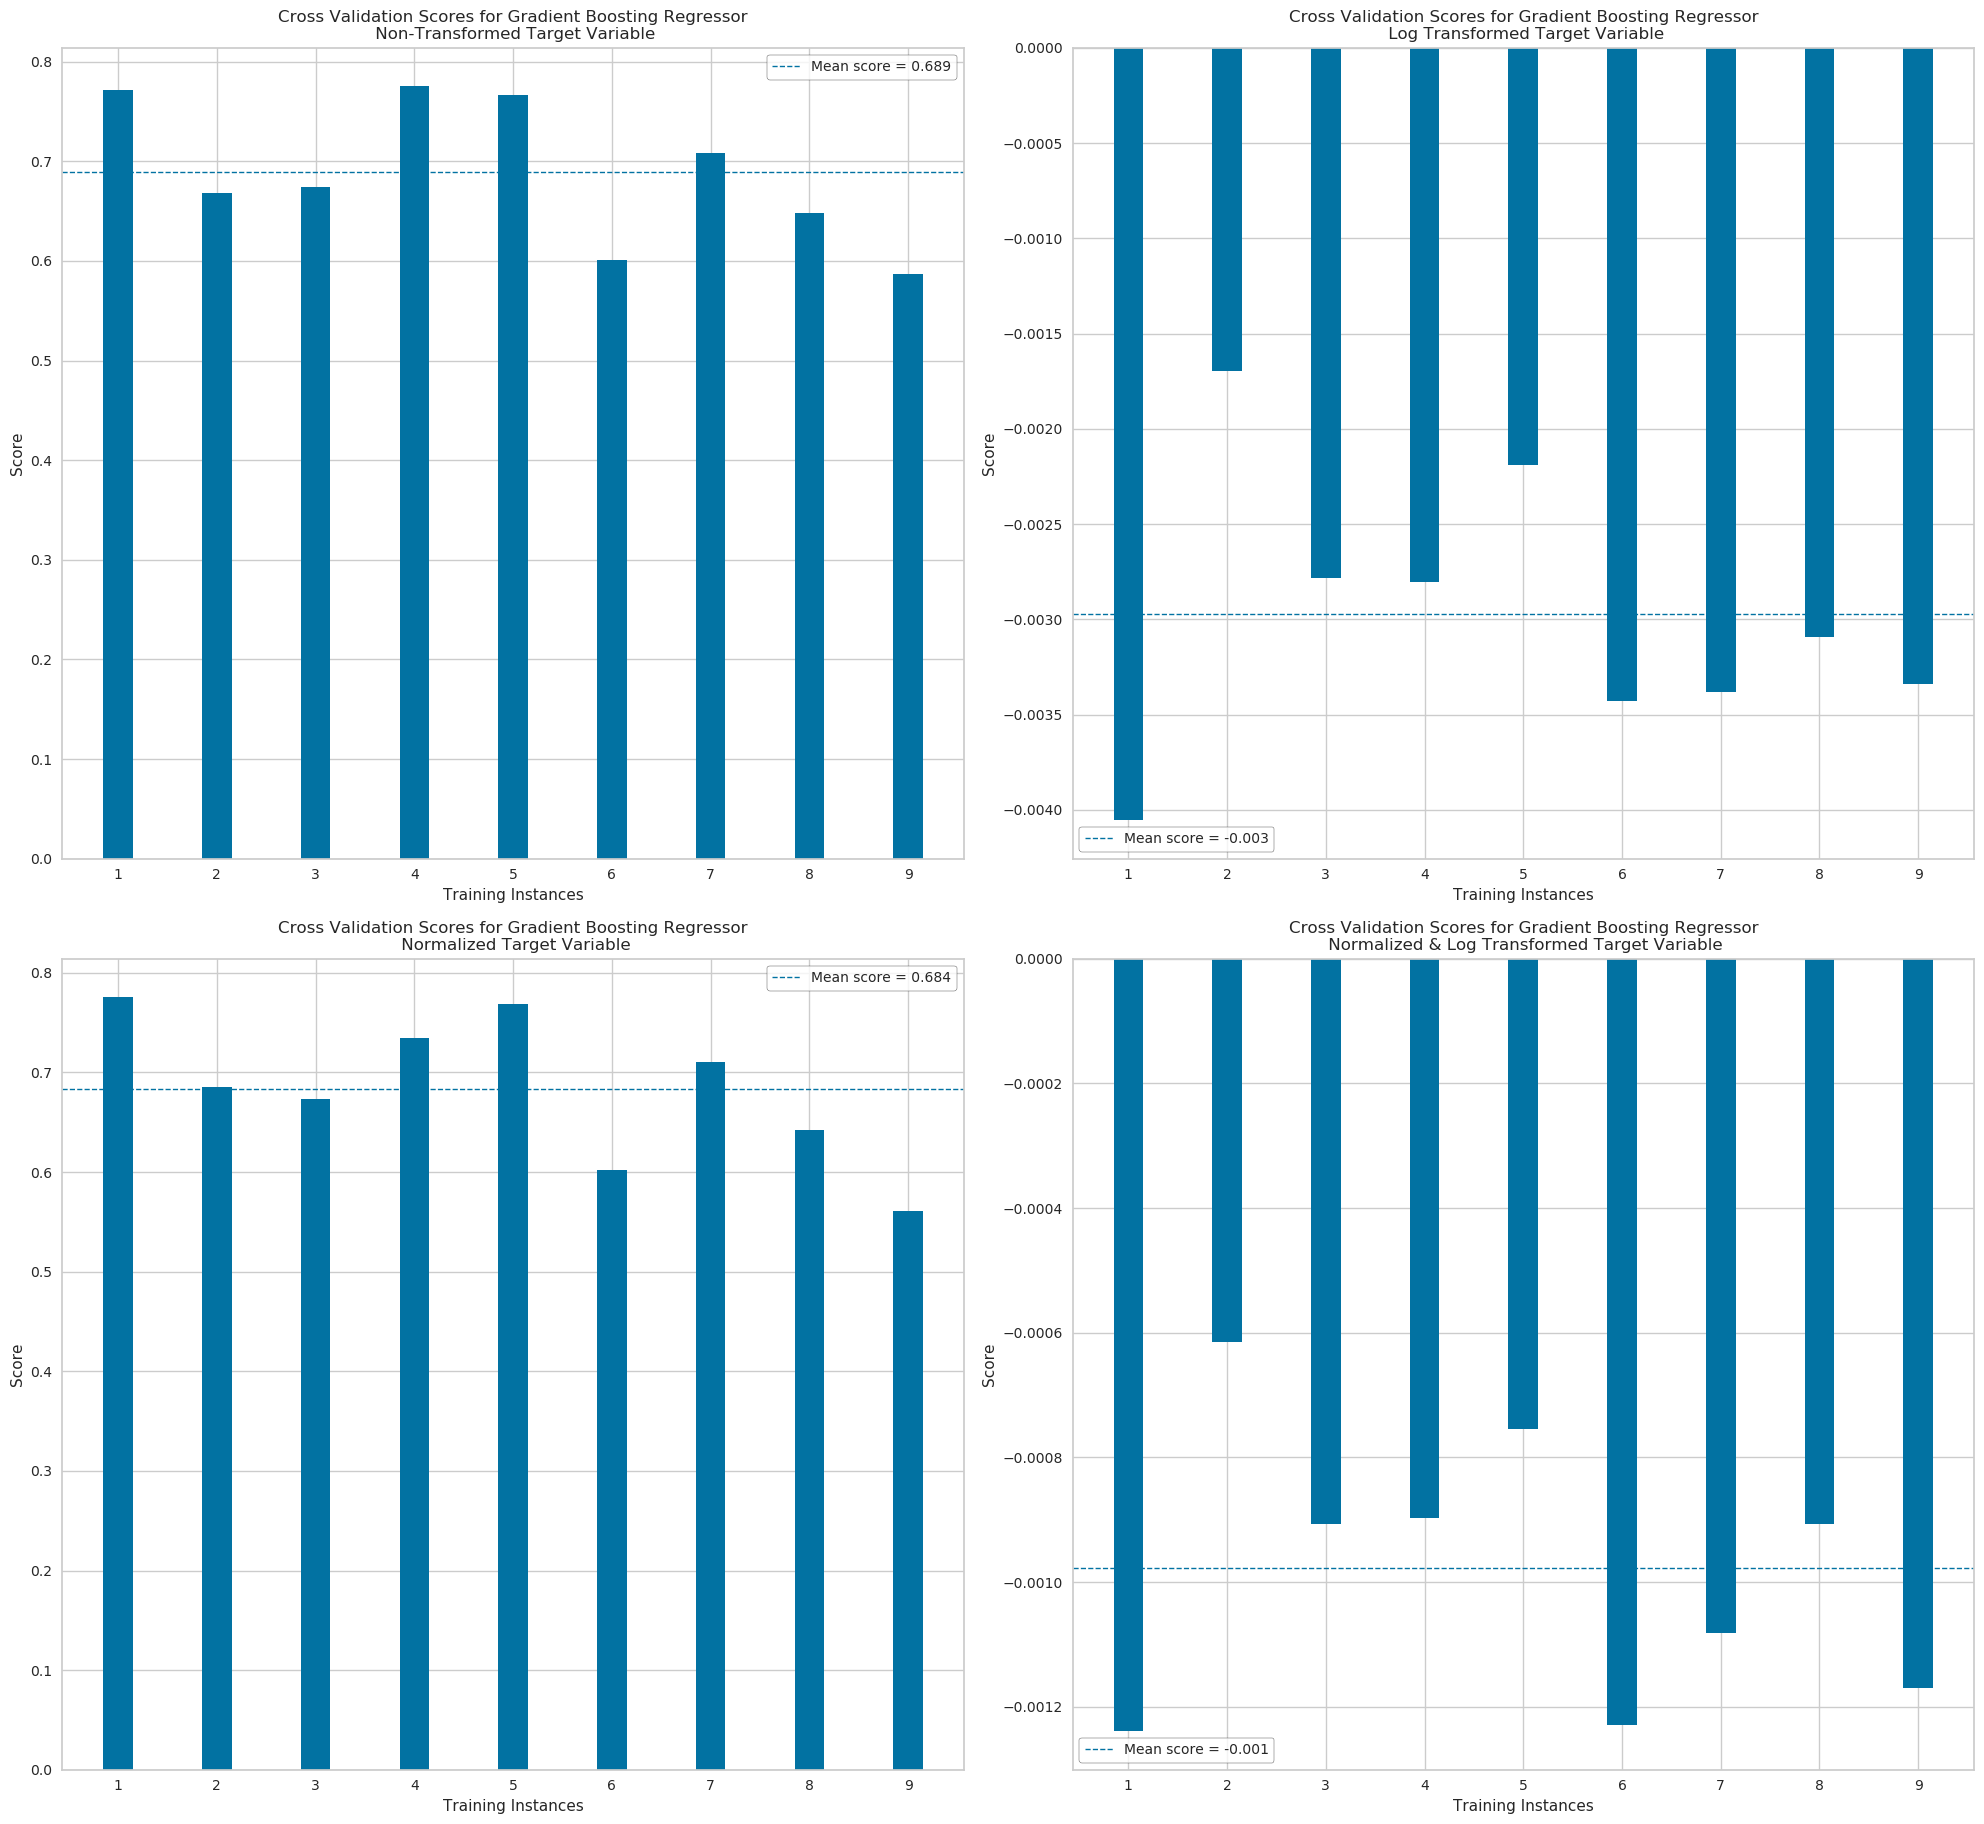

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y, groups=divisions)
model = GradientBoostingRegressor(n_estimators=params0['n_estimators'], max_depth=params0['max_depth'],
                                  learning_rate=params0['learning_rate'], max_features=params0['max_features'],
                                  min_samples_leaf=params0['min_samples_split'], random_state=42)
visualizer0 = CVScores(model, cv=cv, scoring='r2', ax=axes[0])
visualizer0.fit(X[automatic_selected_features], y)
visualizer0.finalize()
axes[0].set_title('Cross Validation Scores for Gradient Boosting Regressor\n Non-Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_log, groups=divisions)
model = GradientBoostingRegressor(n_estimators=params1['n_estimators'], max_depth=params1['max_depth'],
                                  learning_rate=params1['learning_rate'], max_features=params1['max_features'],
                                  min_samples_leaf=params1['min_samples_split'], random_state=42)
visualizer1 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[1])
visualizer1.fit(X[automatic_selected_features], y_log)
visualizer1.finalize()
axes[1].set_title('Cross Validation Scores for Gradient Boosting Regressor\n Log Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_normalized, groups=divisions)
model = GradientBoostingRegressor(n_estimators=params2['n_estimators'], max_depth=params2['max_depth'],
                                  learning_rate=params2['learning_rate'], max_features=params2['max_features'],
                                  min_samples_leaf=params2['min_samples_split'], random_state=42)
visualizer2 = CVScores(model, cv=cv, scoring='r2', ax=axes[2])
visualizer2.fit(X[automatic_selected_features], y_normalized)
visualizer2.finalize()
axes[2].set_title('Cross Validation Scores for Gradient Boosting Regressor\n Normalized Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[automatic_selected_features], y_log_normalized, groups=divisions)
model = GradientBoostingRegressor(n_estimators=params3['n_estimators'], max_depth=params3['max_depth'],
                                  learning_rate=params3['learning_rate'], max_features=params3['max_features'],
                                  min_samples_leaf=params3['min_samples_split'], random_state=42)
visualizer3 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[3])
visualizer3.fit(X[automatic_selected_features], y_log_normalized)
visualizer3.finalize()
axes[3].set_title('Cross Validation Scores for Gradient Boosting Regressor\n Normalized & Log Transformed Target Variable')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../images/crossvalidationscores_automaticfeatures_gradientboosting.png', dpi=300)

In [31]:
params0 = gb_regressor_hyperparametertuning(other_features, y, 'r2')
params1 = gb_regressor_hyperparametertuning(other_features, y_normalized, 'r2')
params2 = gb_regressor_hyperparametertuning(other_features, y_log, 'neg_mean_squared_log_error')
params3 = gb_regressor_hyperparametertuning(other_features, y_log_normalized, 'neg_mean_squared_log_error')

print('\n')
        
average_score_otherfeatures_nontransformed_gb = gb_regressor_crossvalidation(other_features, y, y_train, y_test, 'r2', params0)
average_score_otherfeatures_normalized_gb = gb_regressor_crossvalidation(other_features, y_normalized, y_train_normalized, y_test_normalized, 'r2', params1)
average_score_otherfeatures_log_gb = gb_regressor_crossvalidation(other_features, y_log, y_train_log, y_test_log, 'neg_mean_squared_log_error', params2)
average_score_otherfeatures_log_normalized_gb = gb_regressor_crossvalidation(other_features, y_log_normalized, y_train_log_normalized, y_test_log_normalized, 'neg_mean_squared_log_error', params3)    

Best score is -0.6981
Best parameters for Gradient Boosting Regressor:
            - n_estimators=100
            - max_depth=8
            - learning_rate=0.021415
            - max_features=22
            - min_samples_split=100


Best score is -0.6976
Best parameters for Gradient Boosting Regressor:
            - n_estimators=60
            - max_depth=8
            - learning_rate=0.034257
            - max_features=23
            - min_samples_split=100


Best score is 0.0029
Best parameters for Gradient Boosting Regressor:
            - n_estimators=100
            - max_depth=8
            - learning_rate=0.046881
            - max_features=9
            - min_samples_split=100


Best score is 0.0010
Best parameters for Gradient Boosting Regressor:
            - n_estimators=85
            - max_depth=7
            - learning_rate=0.074302
            - max_features=7
            - min_samples_split=113




CrossValPredict R2 is 0.6326795547049708
TrainTestSplit R2 is 0.61714410

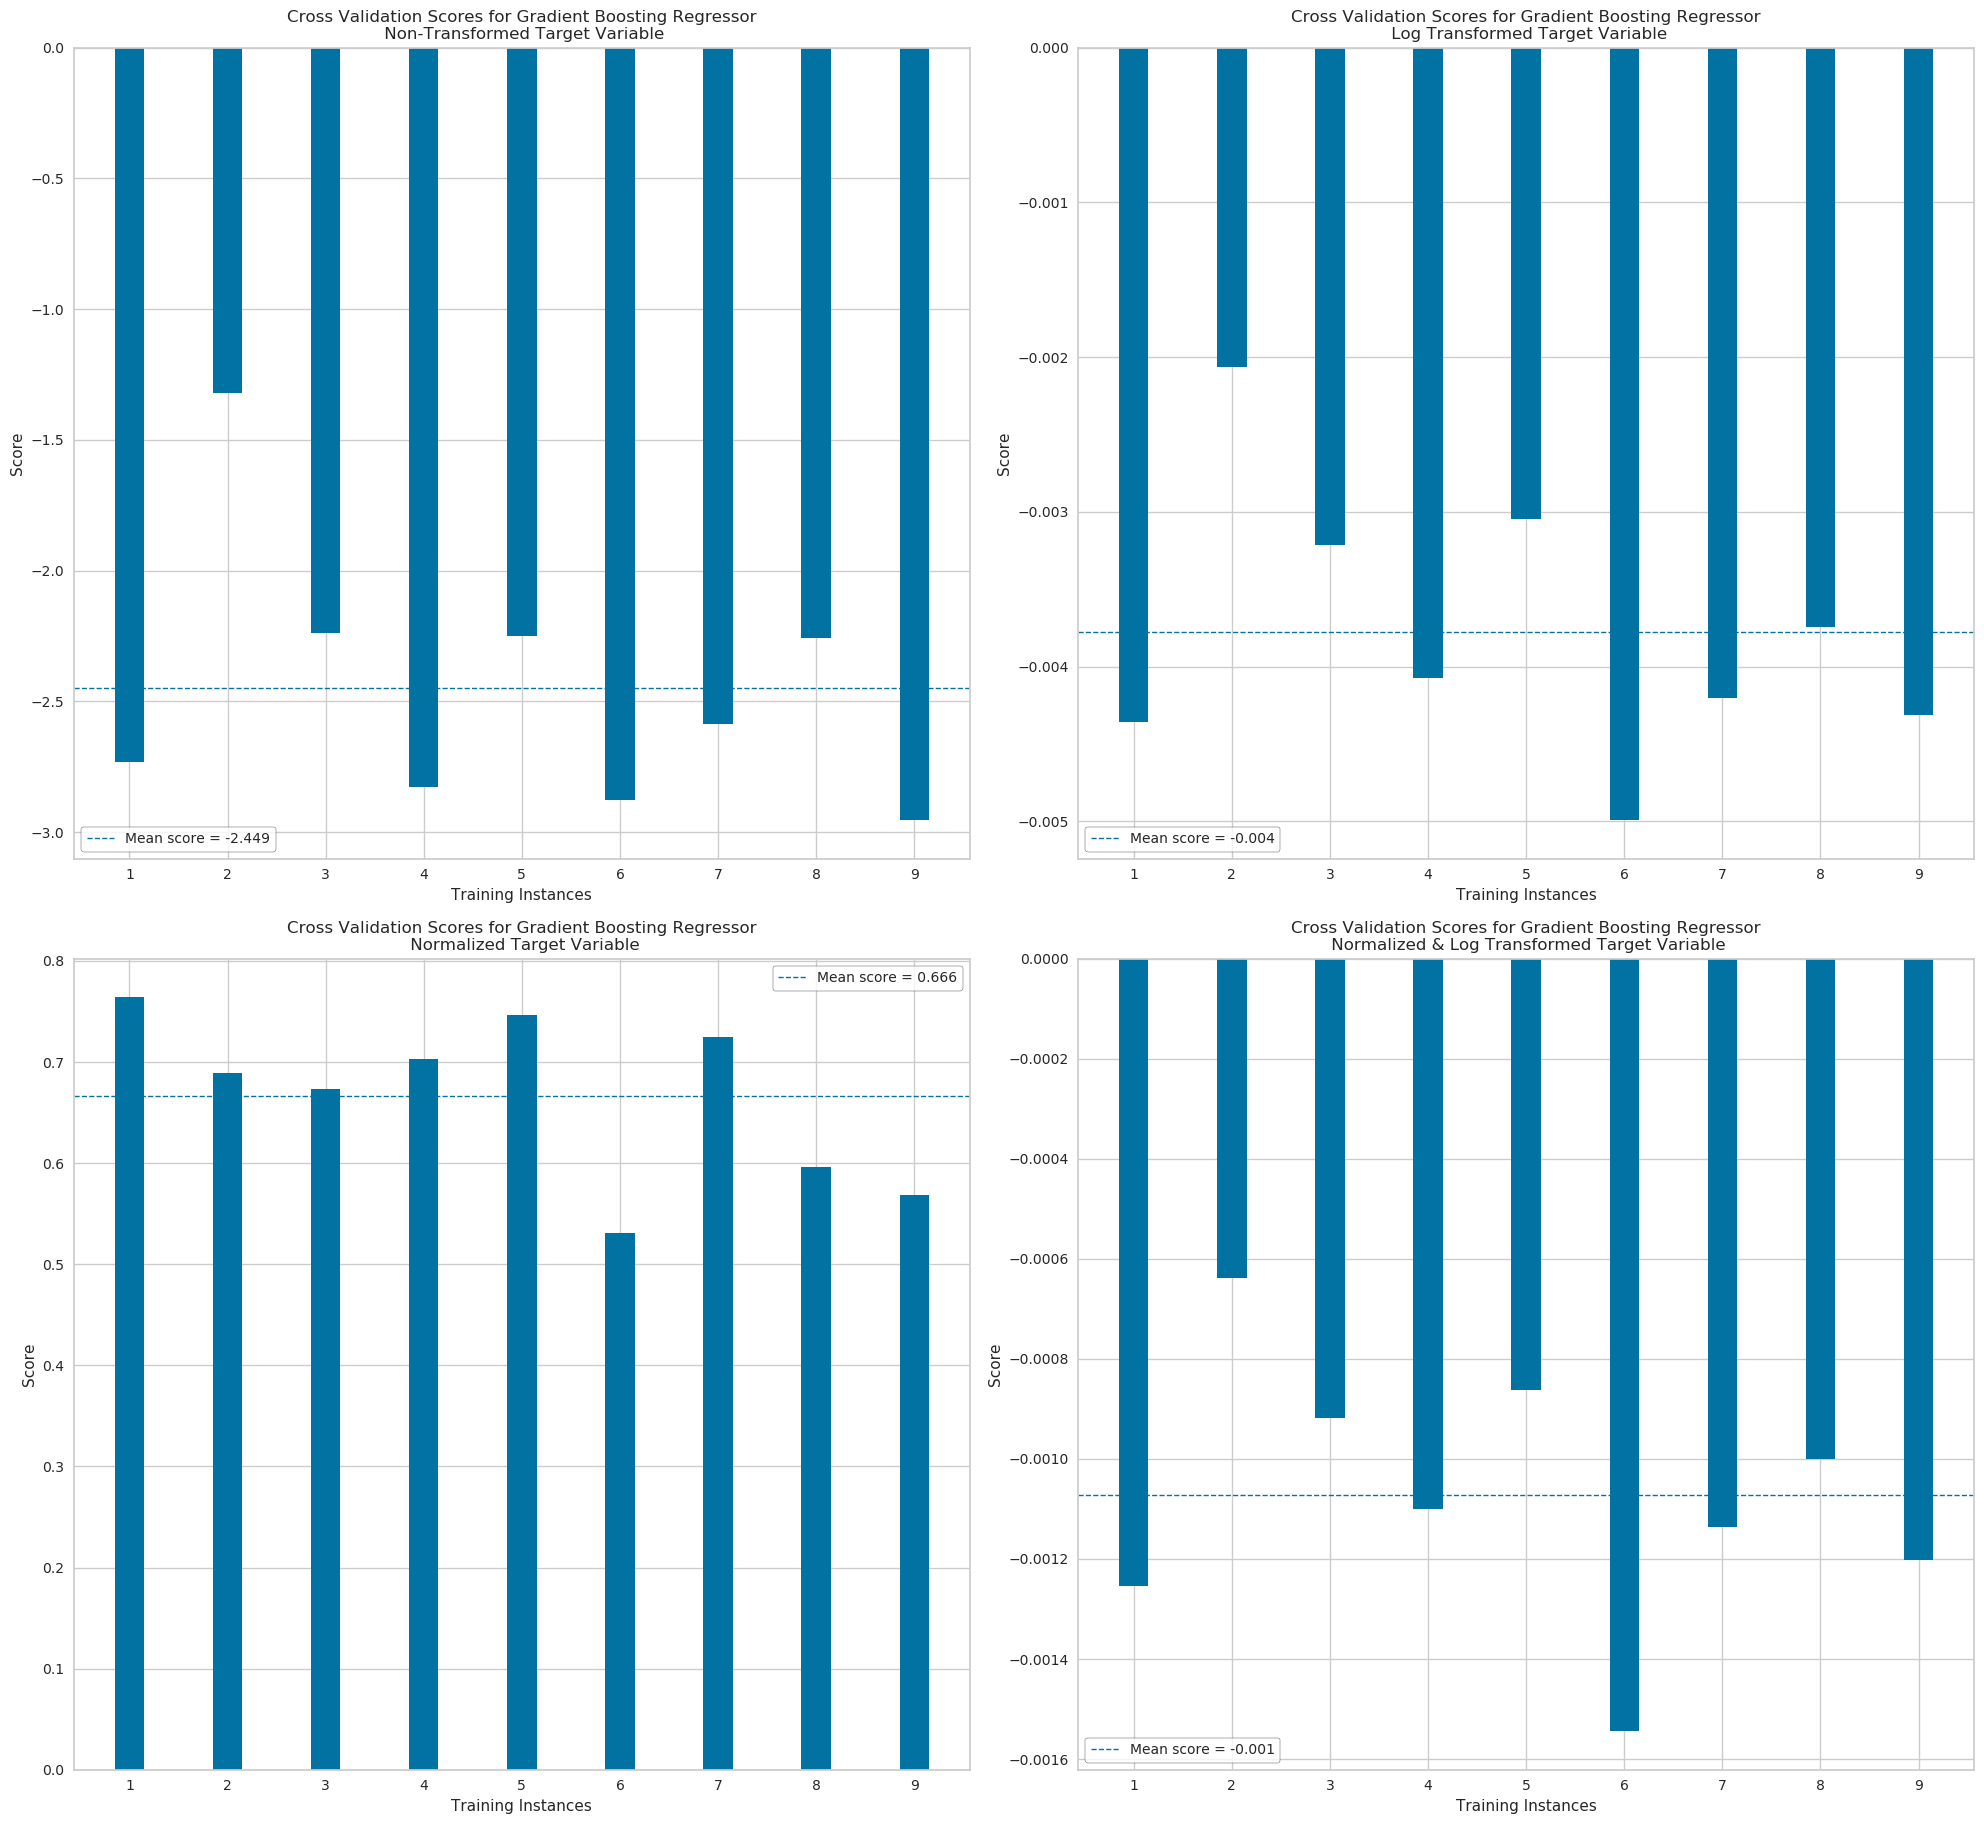

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y, groups=divisions)
model = GradientBoostingRegressor(n_estimators=params0['n_estimators'], max_depth=params0['max_depth'],
                                  learning_rate=params0['learning_rate'], max_features=params0['max_features'],
                                  min_samples_leaf=params0['min_samples_split'], random_state=42)
visualizer0 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[0])
visualizer0.fit(X[other_features], y)
visualizer0.finalize()
axes[0].set_title('Cross Validation Scores for Gradient Boosting Regressor\n Non-Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_log, groups=divisions)
model = GradientBoostingRegressor(n_estimators=params1['n_estimators'], max_depth=params1['max_depth'],
                                  learning_rate=params1['learning_rate'], max_features=params1['max_features'],
                                  min_samples_leaf=params1['min_samples_split'], random_state=42)
visualizer1 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[1])
visualizer1.fit(X[other_features], y_log)
visualizer1.finalize()
axes[1].set_title('Cross Validation Scores for Gradient Boosting Regressor\n Log Transformed Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_normalized, groups=divisions)
model = GradientBoostingRegressor(n_estimators=params2['n_estimators'], max_depth=params2['max_depth'],
                                  learning_rate=params2['learning_rate'], max_features=params2['max_features'],
                                  min_samples_leaf=params2['min_samples_split'], random_state=42)
visualizer2 = CVScores(model, cv=cv, scoring='r2', ax=axes[2])
visualizer2.fit(X[other_features], y_normalized)
visualizer2.finalize()
axes[2].set_title('Cross Validation Scores for Gradient Boosting Regressor\n Normalized Target Variable')

logo = LeaveOneGroupOut()
cv = logo.split(X[other_features], y_log_normalized, groups=divisions)
model = GradientBoostingRegressor(n_estimators=params3['n_estimators'], max_depth=params3['max_depth'],
                                  learning_rate=params3['learning_rate'], max_features=params3['max_features'],
                                  min_samples_leaf=params3['min_samples_split'], random_state=42)
visualizer3 = CVScores(model, cv=cv, scoring='neg_mean_squared_log_error', ax=axes[3])
visualizer3.fit(X[other_features], y_log_normalized)
visualizer3.finalize()
axes[3].set_title('Cross Validation Scores for Gradient Boosting Regressor\n Normalized & Log Transformed Target Variable')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../images/crossvalidationscores_otherfeatures_gradientboosting.png', dpi=300)

In [33]:
print(pd.DataFrame(list(zip(['Non Transformed Target', 'Normalized Target', 'Log Transformation', 'Normalized Log Transformation'], 
                   [average_score_automaticfeatures_nontransformed_gb * -1, average_score_automaticfeatures_normalized_gb * -1,
                    average_score_automaticfeatures_log_gb * -1, average_score_automaticfeatures_log_normalized_gb * -1],
                   [average_score_otherfeatures_nontransformed_gb * -1, average_score_otherfeatures_normalized_gb * -1, 
                    average_score_otherfeatures_log_gb * -1, average_score_otherfeatures_log_normalized_gb * -1])),
                   columns=['Transformation of Target Variable', 'Cross Validated Average MSLE for Automatically Selected Features',
                            'Cross Validated Average MSLE for Other Selected Features']).to_latex(index=False))

\begin{tabular}{lrr}
\toprule
Transformation of Target Variable &  Cross Validated Average MSLE for Automatically Selected Features &  Cross Validated Average MSLE for Other Selected Features \\
\midrule
           Non Transformed Target &                                          -0.688718 &                                          -0.639021 \\
                Normalized Target &                                          -0.699811 &                                          -0.636346 \\
               Log Transformation &                                           0.002965 &                                           0.003244 \\
    Normalized Log Transformation &                                           0.000978 &                                           0.001072 \\
\bottomrule
\end{tabular}



# **Compare Model Scores**

In [34]:
scores = [average_score_automaticfeatures_nontransformed_rf * -1, average_score_automaticfeatures_normalized_rf * -1, average_score_automaticfeatures_log_rf * -1, average_score_automaticfeatures_log_normalized_rf * -1,
          average_score_automaticfeatures_nontransformed_knn * -1, average_score_automaticfeatures_normalized_knn * -1, average_score_automaticfeatures_log_knn * -1, average_score_automaticfeatures_log_normalized_knn * -1,
          average_score_automaticfeatures_nontransformed_ab * -1, average_score_automaticfeatures_normalized_ab * -1, average_score_automaticfeatures_log_ab * -1, average_score_automaticfeatures_log_normalized_ab * -1, 
          average_score_automaticfeatures_nontransformed_gb * -1, average_score_automaticfeatures_normalized_gb * -1, average_score_automaticfeatures_log_gb * -1, average_score_automaticfeatures_log_normalized_gb * -1,
          average_score_otherfeatures_nontransformed_rf * -1, average_score_otherfeatures_normalized_rf * -1, average_score_otherfeatures_log_rf * -1, average_score_otherfeatures_log_normalized_rf * -1,
          average_score_otherfeatures_nontransformed_knn * -1, average_score_otherfeatures_normalized_knn * -1, average_score_otherfeatures_log_knn * -1, average_score_otherfeatures_log_normalized_knn * -1,
          average_score_otherfeatures_nontransformed_ab * -1, average_score_otherfeatures_normalized_ab * -1, average_score_otherfeatures_log_ab * -1, average_score_otherfeatures_log_normalized_ab * -1, 
          average_score_otherfeatures_nontransformed_gb * -1, average_score_otherfeatures_normalized_gb * -1, average_score_otherfeatures_log_gb * -1, average_score_otherfeatures_log_normalized_gb * -1]

target_variable_types = ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed'] * 8

model_types = [['Random Forest'] * 4, ['KNN'] * 4, ['AdaBoost'] * 4,  ['Gradient Boost'] * 4] * 2
model_types = [item for sublist in model_types for item in sublist]

feature_set_types = [['Automatically Selected Features'] * 16, ['Other Features'] * 16]
feature_set_types = [item for sublist in feature_set_types for item in sublist]

all_scores = pd.DataFrame(list(zip(model_types, feature_set_types, target_variable_types, scores)), columns=['Model Algorithm', 'Feature Set', 'Target Variable Transformation', 'Cross Validated Average MSLE Score'])
all_scores = all_scores.sort_values(by='Cross Validated Average MSLE Score', ascending=True)
print(all_scores.to_latex(index=False))

\begin{tabular}{lllr}
\toprule
Model Algorithm &                     Feature Set & Target Variable Transformation &  Cross Validated Average MSLE Score \\
\midrule
 Gradient Boost & Automatically Selected Features &                     Normalized &                           -0.699811 \\
 Gradient Boost & Automatically Selected Features &                Non-Transformed &                           -0.688718 \\
 Gradient Boost &                  Other Features &                Non-Transformed &                           -0.639021 \\
 Gradient Boost &                  Other Features &                     Normalized &                           -0.636346 \\
  Random Forest & Automatically Selected Features &                     Normalized &                            0.000332 \\
            KNN & Automatically Selected Features &                     Normalized &                            0.000370 \\
  Random Forest &                  Other Features &                     Normalized &        